In [1]:
from typing import Tuple, List, Optional, Dict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import lightgbm as lgb

import graphviz

from sklearn import linear_model
from sklearn import tree
from imblearn.over_sampling import SMOTENC
from sklearn.model_selection import StratifiedKFold

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder as OHE

from sksurv.datasets import get_x_y
from sksurv.ensemble import RandomSurvivalForest, GradientBoostingSurvivalAnalysis, ComponentwiseGradientBoostingSurvivalAnalysis, ExtraSurvivalTrees
from sksurv.linear_model import CoxPHSurvivalAnalysis

from utils import *

# Enable higher resolution plots
%config InlineBackend.figure_format = 'retina'

# Autoreload modules
%reload_ext autoreload
%autoreload 2

In [2]:
pd.set_option('display.max_columns', None) # display all columns when plotting a dataframe

In [3]:
unimputed_df_0 = pd.read_csv('datasets/final_dataset_unimputed.csv').set_index('USUBJID')

categorical_cols = unimputed_df_0.select_dtypes(include=object).columns.to_list()
unimputed_df_0[categorical_cols] = unimputed_df_0[categorical_cols].astype(str)
unimputed_df_0['EVENT'] = unimputed_df_0['EVENT'].astype(str)

## One-Hot-Encoded Dataset
encoded_unimputed_df_0 = pd.read_csv('datasets/final_dataset_encoded_unimputed.csv').set_index('USUBJID')

encoded_unimputed_df_0['EVENT'] = encoded_unimputed_df_0['EVENT'].astype(str)

In [4]:
numerical_cols_to_impute = unimputed_df_0.drop(columns=['TIME_IN_DAYS']).select_dtypes(exclude=object).columns.to_list()

In [5]:
missing_values(unimputed_df_0)

,Complement C3c,Cystatin C,High Sensitivity C-reactive Protein,Monocyte Chemotactic Protein 1,Albumin,Alpha-1 Globulin,Cystatine C,Kidney Injury Molecule,Protein,Urine glucose,3 POINT GRIP,FINGER PINCH GRIP,PICKING UP COINS,PLACING FINGER ON NUMBER DIAGRAM,PUSH ON THE LIGHT,SUPINATION,THUMB (KEY) GRIP,TRACING PATH,SHOULDER ABDUCTION TO SHOULDER HEIGHT,SHOULDER ABDUCTION ABOVE SHOULDER HEIGHT,SHOULDER FLEXION TO SHOULDER HEIGHT,SHOULDER FLEXION ABOVE SHOULDER HEIGHT,HAND(S) TO TABLE FROM LAP,HAND(S) TO MOUTH,LIFTING HEAVY CANS,LIFTING LIGHT CANS,MOVE WEIGHT ON TABLE,REMOVE LID FROM CONTAINER,STACKING HEAVY CANS,STACKING LIGHT CANS,TEARING PAPER,PREFERRED ARM,ELBOW CONTRACTURES,SPINAL SURGERY,ECGRES,PR,QRS,QT,QTc,NSAA,CLIMB BOX STEP - LEFT,CLIMB BOX STEP - RIGHT,DESCEND BOX STEP - LEFT,DESCEND BOX STEP - RIGHT,GETS TO SITTING,HOP LEFT LEG,HOP RIGHT LEG,JUMP,LIFTS HEAD,RISE FROM FLOOR,RUN(10M),STAND,STAND UP FROM CHAIR,STANDS ON HEELS,STAND ON ONE LEG - LEFT,STAND ON ONE LEG - RIGHT,WALK,BMMODEL,BONE MINERAL CONTENT,WHOLE BODY FAT TISSUE MASS,WHOLE BODY LEAN TISSUE MASS,FRACTIONAL SHORTENING,LEFT POSTERIOR WALL THICKNESS,LEFT SEPTUM WALL THICKNESS,LV END DIASTOLIC DIAMETER,LVEF,LV END SYSTOLIC DIAMETER,LEFT ANKLE DORSIFLEXION (SITTING),RIGHT ANKLE DORSIFLEXION (SITTING),ELBOW EXTENSION(LEFT),ELBOW EXTENSION (RIGHT),LEFT HIP EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),RIGHT HIP EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),LEFT ILIO TIBIAL BANDS (SUPINE-AMBULANT PATIENTS ONLY),RIGHT ILIO TIBIAL BANDS (SUPINE-AMBULANT PATIENTS ONLY),LEFT KNEE EXTENSION (SITTING),RIGHT KNEE EXTENSION (SITTING),SHOULDER FLEXION (LEFT),SHOULDER FLEXION (RIGHT),WRIST EXTENSION (LEFT),WRIST EXTENSION (RIGHT),ELBOW EXTENSOR,ELBOW FLEXOR,KNEE EXTENSOR,SHOULDER FLEXOR,SUPINE ELBOW EXTENSOR,SUPINE ELBOW FLEXOR,WRIST EXTENSOR,LEFT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY),RIGHT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY),LEFT KNEE EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),RIGHT KNEE EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),ABDOM,CARDSYS,EAR,EYES,HAIR,LYNDS,MNTST,MUSSYS,NURSYS,RESSYS,SKIN,THROAT,6MWD_AIDS,6MWD_SHOES,6MWD_DISWLK,6MWD_NOFALL,10MWALK,10MWR_AIDS,10MWR_SHOES,4SCA_4-AGRAD,4SCA_AIDS,4SCA_SHOES,4SCD_4-AGRAD,4SCD_AIDS,4SCD_SHOES,RISE_FROM_FLOOR,FEV1,FEV1%,FVC,FVC%,MEP,MIP,PCF,PF,PF%,BMI,DIASBP,HEIGHT,HR,RR,SYSBP,WEIGHT,RACE,ETHNIC,MHINT,MUTATION_TYPE,PRESENT_STEROID_USE,PAST_STEROID_USE,MUTATION_LOCATION,STEROID_CM,STEROID_DOSE,STEROID_FRQ,OSTEOPOROSIS_PREVENTION,AGE_DIAGNOSIS,CURRENT_AGE,HOTSPOT_MUTATION,AGE_AMBULATORY_ASSISTANCE,AGE_LORDOSIS,AGE_CONTRACTURE,AGE_GOWERS_MANOEUVRE,EVENT,TIME_IN_DAYS
Total,15,15,14,20,9,10,50,10,9,9,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,92,90,91,91,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,128,140,140,111,123,124,106,121,118,11,11,6,6,8,8,9,9,10,10,7,6,6,5,15,15,18,17,76,96,18,8,8,8,8,0,0,0,0,0,0,0,0,0,0,0,0,0,0,16,16,0,0,0,0,0,0,0,0,0,0,50,63,42,53,114,121,118,60,101,2,11,3,4,45,11,2,0,0,0,0,0,0,0,0,0,0,13,0,0,0,144,172,162,130,0,0
Percent(%),6.849315,6.849315,6.392694,9.13242,4.109589,4.56621,22.83105,4.56621,4.109589,4.109589,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,42.009132,41.09589,41.552511,41.552511,1.826484,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,58.447489,63.926941,63.926941,50.684932,56.164384,56.621005,48.401826,55.251142,53.881279,5.022831,5.022831,2.739726,2.739726,3.652968,3.652968,4.109589,4.109589,4.56621,4.56621,3.196347,2.739726,2.739726,2.283105,6.849315,6.849315,8.219178,7.762557,34.703196,43.835616,8.219178,3.652968,3.652968,3.652968,3.652968,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.305936,7.305936,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,22.83105,28.767123,19.178082,24.200913,52.054795,55.251142,53.881279,27.39726,46.118721,0.913242,5.022831,1.369863,1.826484,20.547945,5.022831,0.913242,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.936073,0.0,0.0,0.0,65.753425,78.538813,73.9726

## Experiments with 5-fold Cross-Validation

First we create the folds. 

In [7]:
folds = list(create_train_test_folds(unimputed_df_0, ['EVENT', 'TIME_IN_DAYS'], 5))

### Ensemble Machine Learning Algorithms

#### CatBoost Algorithm with `imputed_df_0`

In [9]:
import warnings
warnings.filterwarnings("ignore")

### CatBoost

Running fold 0 ...
['3 POINT GRIP', 'FINGER PINCH GRIP', 'PICKING UP COINS', 'PLACING FINGER ON NUMBER DIAGRAM', 'PUSH ON THE LIGHT', 'SUPINATION', 'THUMB (KEY) GRIP', 'TRACING PATH', 'SHOULDER ABDUCTION TO SHOULDER HEIGHT', 'SHOULDER ABDUCTION ABOVE SHOULDER HEIGHT', 'SHOULDER FLEXION TO SHOULDER HEIGHT', 'SHOULDER FLEXION ABOVE SHOULDER HEIGHT', 'HAND(S) TO TABLE FROM LAP', 'HAND(S) TO MOUTH', 'LIFTING HEAVY CANS', 'LIFTING LIGHT CANS', 'MOVE WEIGHT ON TABLE', 'REMOVE LID FROM CONTAINER', 'STACKING HEAVY CANS', 'STACKING LIGHT CANS', 'TEARING PAPER', 'PREFERRED ARM', 'ELBOW CONTRACTURES', 'SPINAL SURGERY', 'ECGRES', 'CLIMB BOX STEP - LEFT', 'CLIMB BOX STEP - RIGHT', 'DESCEND BOX STEP - LEFT', 'DESCEND BOX STEP - RIGHT', 'GETS TO SITTING', 'HOP LEFT LEG', 'HOP RIGHT LEG', 'JUMP', 'LIFTS HEAD', 'RISE FROM FLOOR', 'RUN(10M)', 'STAND', 'STAND UP FROM CHAIR', 'STANDS ON HEELS', 'STAND ON ONE LEG - LEFT', 'STAND ON ONE LEG - RIGHT', 'WALK', 'BMMODEL', 'ABDOM', 'CARDSYS', 'EAR', 'EYES', 'HA

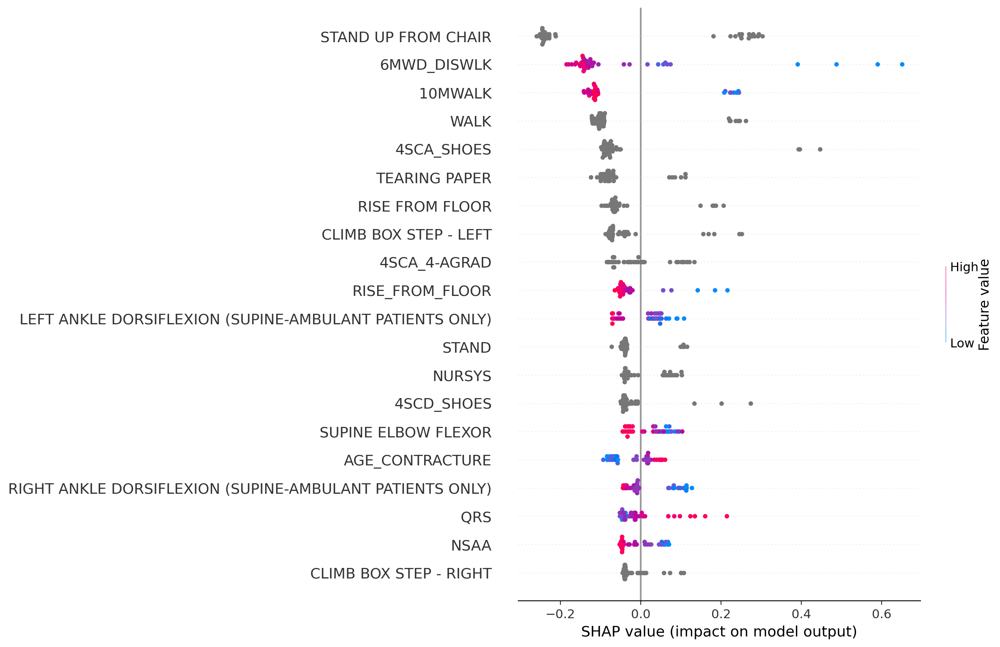

None
Regressor SHAP values


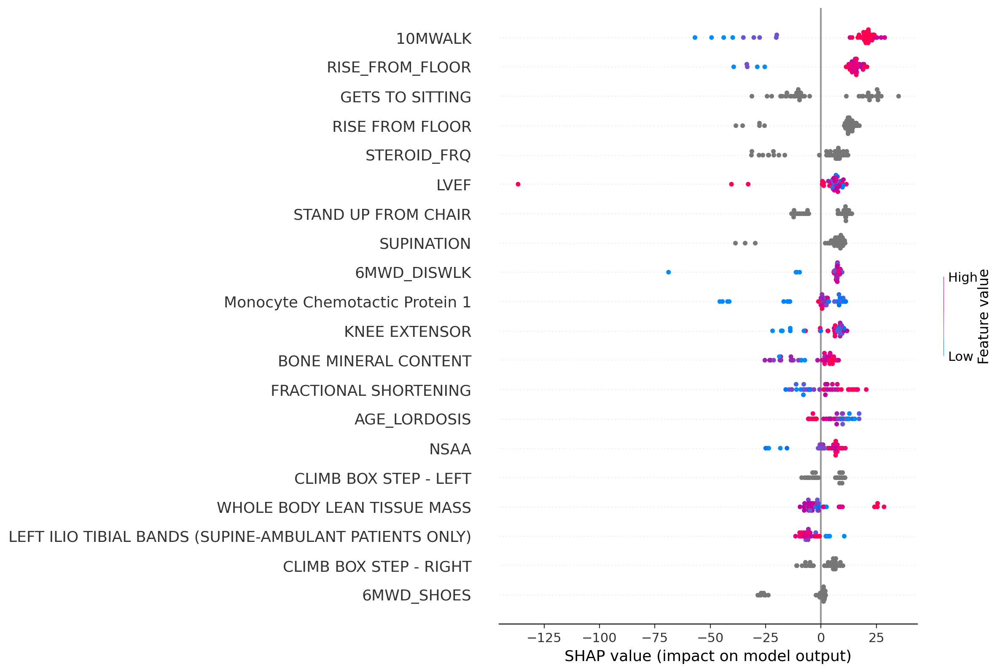

None
Running fold 1 ...
['3 POINT GRIP', 'FINGER PINCH GRIP', 'PICKING UP COINS', 'PLACING FINGER ON NUMBER DIAGRAM', 'PUSH ON THE LIGHT', 'SUPINATION', 'THUMB (KEY) GRIP', 'TRACING PATH', 'SHOULDER ABDUCTION TO SHOULDER HEIGHT', 'SHOULDER ABDUCTION ABOVE SHOULDER HEIGHT', 'SHOULDER FLEXION TO SHOULDER HEIGHT', 'SHOULDER FLEXION ABOVE SHOULDER HEIGHT', 'HAND(S) TO TABLE FROM LAP', 'HAND(S) TO MOUTH', 'LIFTING HEAVY CANS', 'LIFTING LIGHT CANS', 'MOVE WEIGHT ON TABLE', 'REMOVE LID FROM CONTAINER', 'STACKING HEAVY CANS', 'STACKING LIGHT CANS', 'TEARING PAPER', 'PREFERRED ARM', 'ELBOW CONTRACTURES', 'SPINAL SURGERY', 'ECGRES', 'CLIMB BOX STEP - LEFT', 'CLIMB BOX STEP - RIGHT', 'DESCEND BOX STEP - LEFT', 'DESCEND BOX STEP - RIGHT', 'GETS TO SITTING', 'HOP LEFT LEG', 'HOP RIGHT LEG', 'JUMP', 'LIFTS HEAD', 'RISE FROM FLOOR', 'RUN(10M)', 'STAND', 'STAND UP FROM CHAIR', 'STANDS ON HEELS', 'STAND ON ONE LEG - LEFT', 'STAND ON ONE LEG - RIGHT', 'WALK', 'BMMODEL', 'ABDOM', 'CARDSYS', 'EAR', 'EYES'

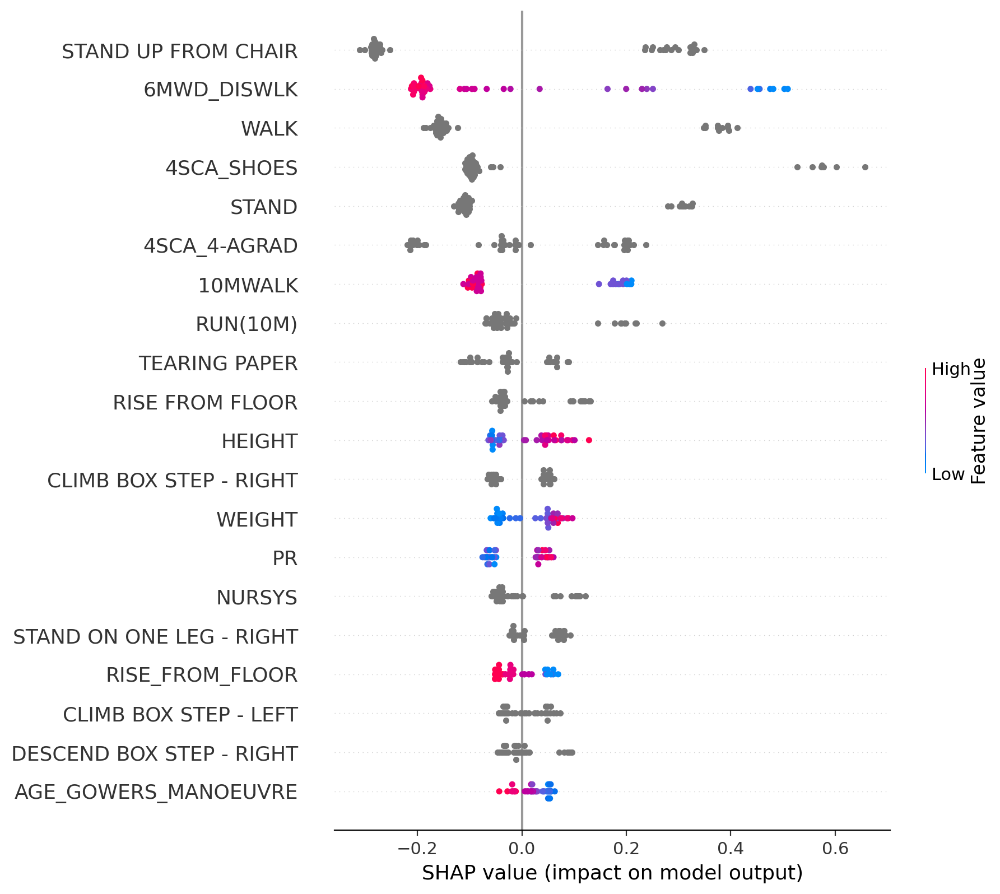

None
Regressor SHAP values


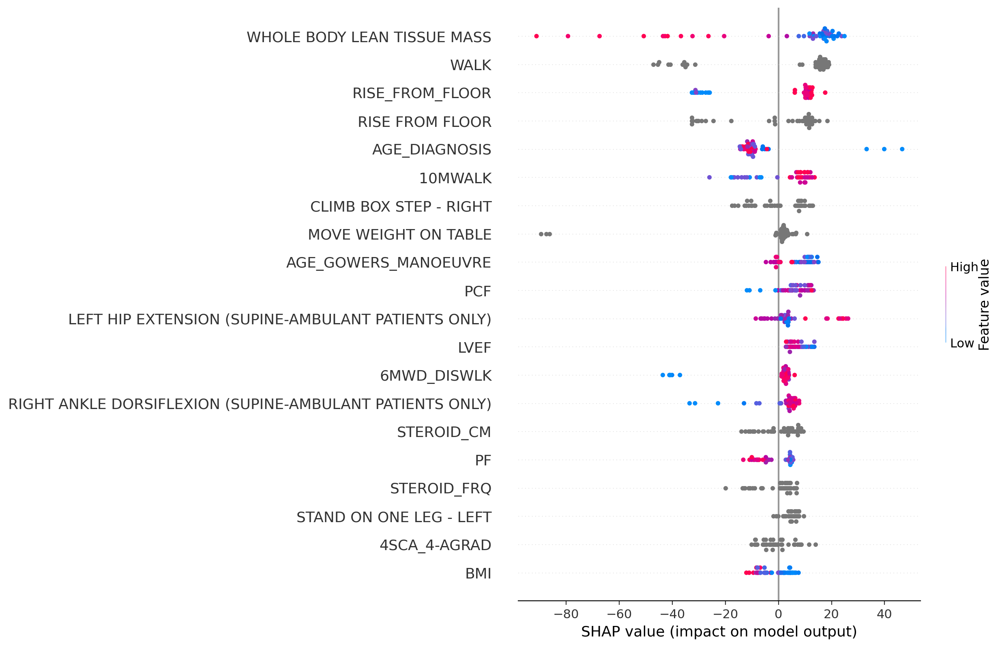

None
Running fold 2 ...
['3 POINT GRIP', 'FINGER PINCH GRIP', 'PICKING UP COINS', 'PLACING FINGER ON NUMBER DIAGRAM', 'PUSH ON THE LIGHT', 'SUPINATION', 'THUMB (KEY) GRIP', 'TRACING PATH', 'SHOULDER ABDUCTION TO SHOULDER HEIGHT', 'SHOULDER ABDUCTION ABOVE SHOULDER HEIGHT', 'SHOULDER FLEXION TO SHOULDER HEIGHT', 'SHOULDER FLEXION ABOVE SHOULDER HEIGHT', 'HAND(S) TO TABLE FROM LAP', 'HAND(S) TO MOUTH', 'LIFTING HEAVY CANS', 'LIFTING LIGHT CANS', 'MOVE WEIGHT ON TABLE', 'REMOVE LID FROM CONTAINER', 'STACKING HEAVY CANS', 'STACKING LIGHT CANS', 'TEARING PAPER', 'PREFERRED ARM', 'ELBOW CONTRACTURES', 'SPINAL SURGERY', 'ECGRES', 'CLIMB BOX STEP - LEFT', 'CLIMB BOX STEP - RIGHT', 'DESCEND BOX STEP - LEFT', 'DESCEND BOX STEP - RIGHT', 'GETS TO SITTING', 'HOP LEFT LEG', 'HOP RIGHT LEG', 'JUMP', 'LIFTS HEAD', 'RISE FROM FLOOR', 'RUN(10M)', 'STAND', 'STAND UP FROM CHAIR', 'STANDS ON HEELS', 'STAND ON ONE LEG - LEFT', 'STAND ON ONE LEG - RIGHT', 'WALK', 'BMMODEL', 'ABDOM', 'CARDSYS', 'EAR', 'EYES'

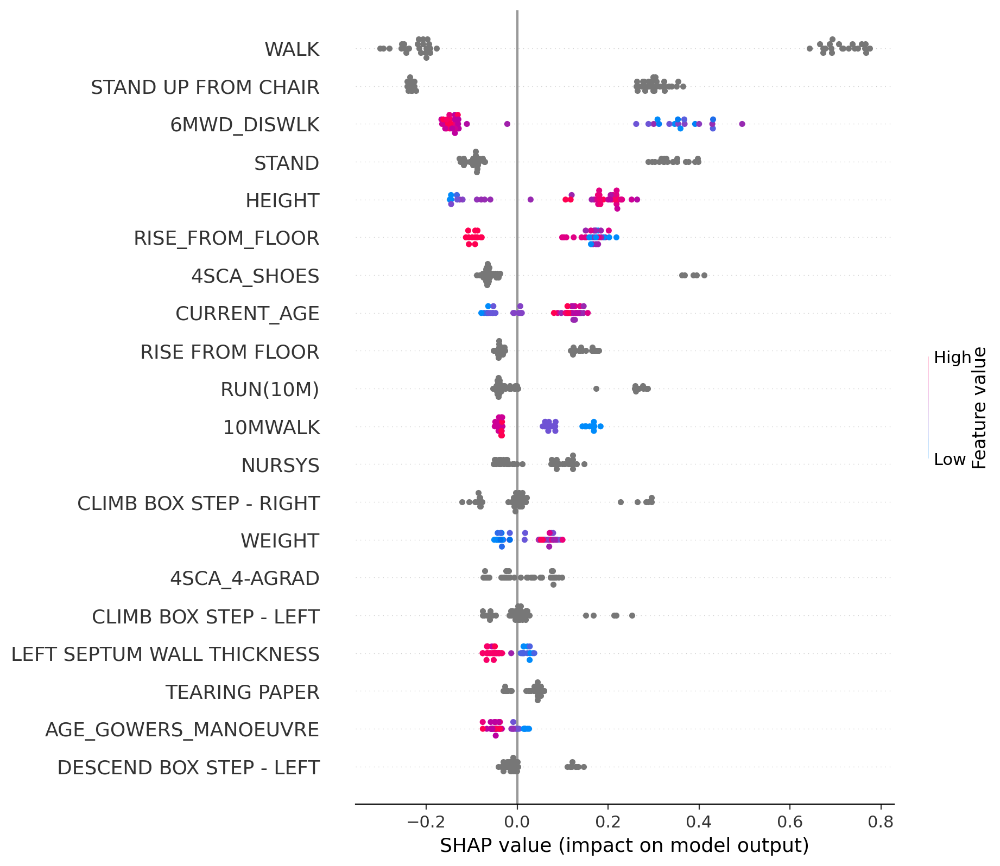

None
Regressor SHAP values


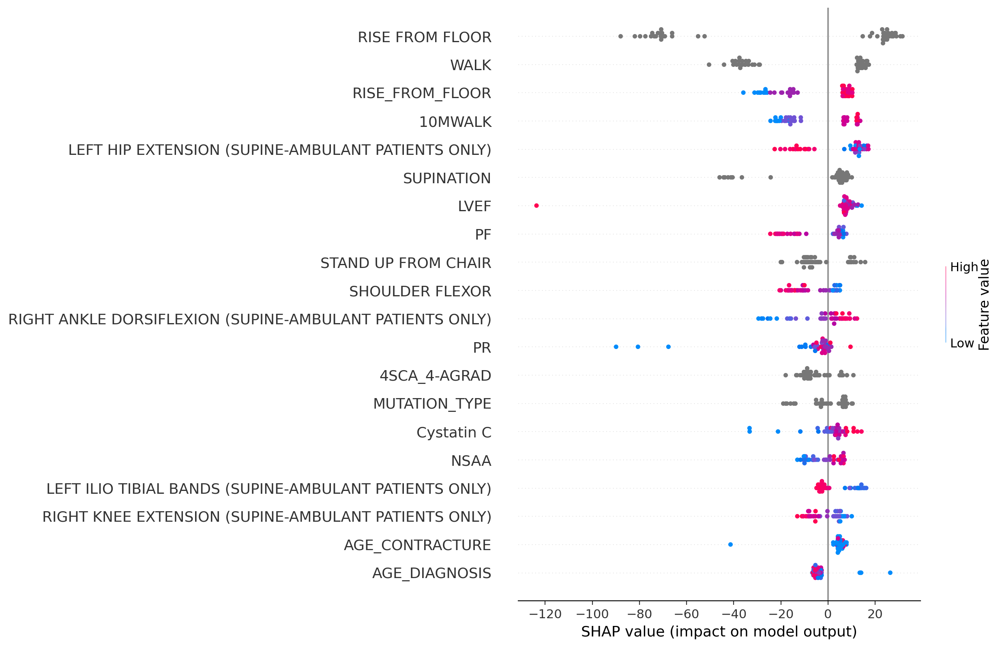

None
Running fold 3 ...
['3 POINT GRIP', 'FINGER PINCH GRIP', 'PICKING UP COINS', 'PLACING FINGER ON NUMBER DIAGRAM', 'PUSH ON THE LIGHT', 'SUPINATION', 'THUMB (KEY) GRIP', 'TRACING PATH', 'SHOULDER ABDUCTION TO SHOULDER HEIGHT', 'SHOULDER ABDUCTION ABOVE SHOULDER HEIGHT', 'SHOULDER FLEXION TO SHOULDER HEIGHT', 'SHOULDER FLEXION ABOVE SHOULDER HEIGHT', 'HAND(S) TO TABLE FROM LAP', 'HAND(S) TO MOUTH', 'LIFTING HEAVY CANS', 'LIFTING LIGHT CANS', 'MOVE WEIGHT ON TABLE', 'REMOVE LID FROM CONTAINER', 'STACKING HEAVY CANS', 'STACKING LIGHT CANS', 'TEARING PAPER', 'PREFERRED ARM', 'ELBOW CONTRACTURES', 'SPINAL SURGERY', 'ECGRES', 'CLIMB BOX STEP - LEFT', 'CLIMB BOX STEP - RIGHT', 'DESCEND BOX STEP - LEFT', 'DESCEND BOX STEP - RIGHT', 'GETS TO SITTING', 'HOP LEFT LEG', 'HOP RIGHT LEG', 'JUMP', 'LIFTS HEAD', 'RISE FROM FLOOR', 'RUN(10M)', 'STAND', 'STAND UP FROM CHAIR', 'STANDS ON HEELS', 'STAND ON ONE LEG - LEFT', 'STAND ON ONE LEG - RIGHT', 'WALK', 'BMMODEL', 'ABDOM', 'CARDSYS', 'EAR', 'EYES'

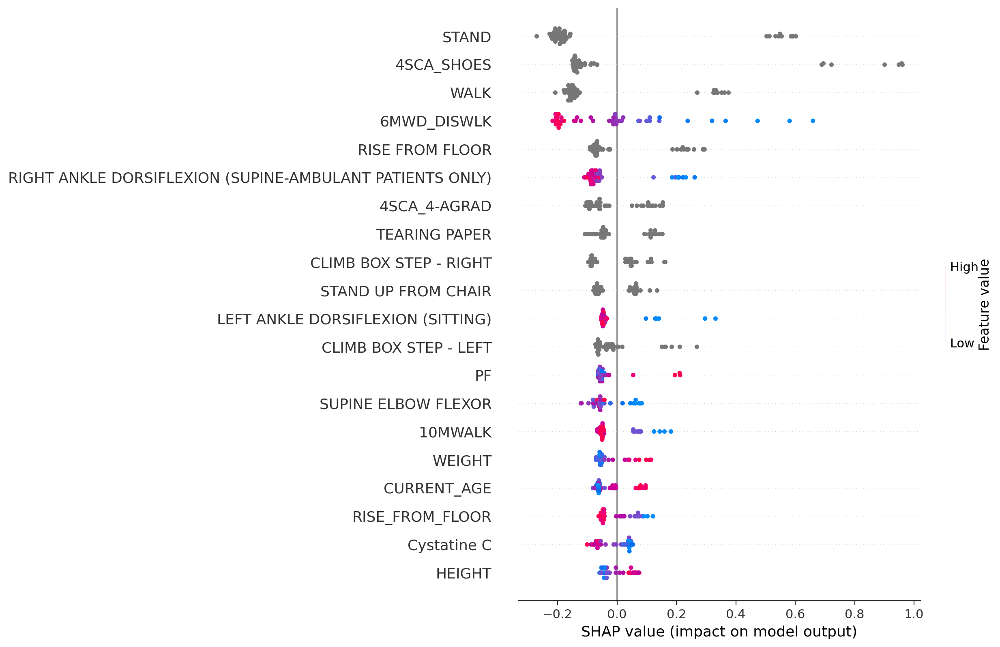

None
Regressor SHAP values


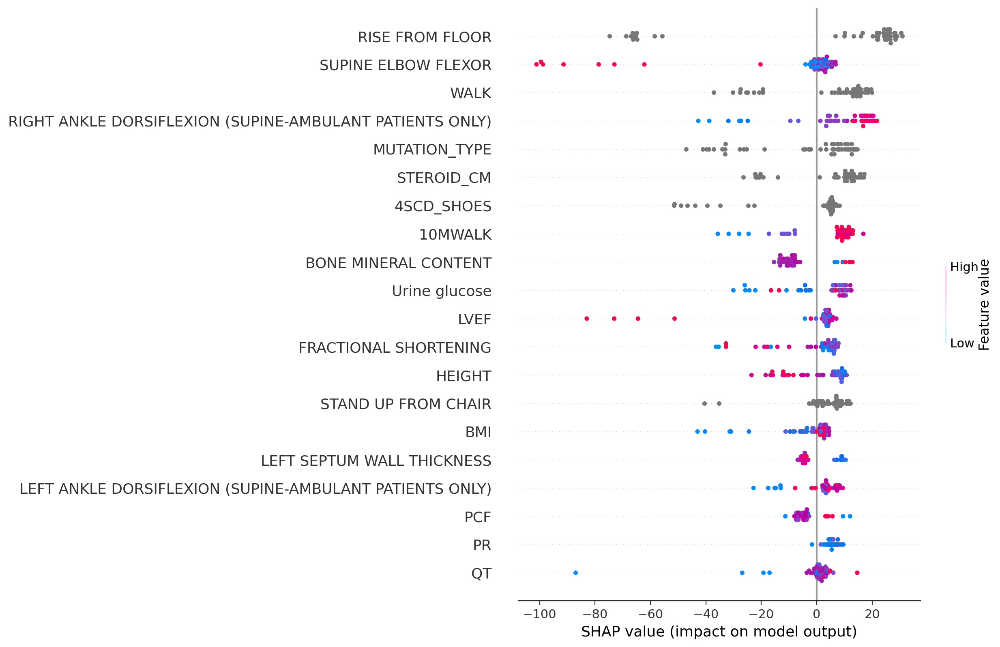

None
Running fold 4 ...
['3 POINT GRIP', 'FINGER PINCH GRIP', 'PICKING UP COINS', 'PLACING FINGER ON NUMBER DIAGRAM', 'PUSH ON THE LIGHT', 'SUPINATION', 'THUMB (KEY) GRIP', 'TRACING PATH', 'SHOULDER ABDUCTION TO SHOULDER HEIGHT', 'SHOULDER ABDUCTION ABOVE SHOULDER HEIGHT', 'SHOULDER FLEXION TO SHOULDER HEIGHT', 'SHOULDER FLEXION ABOVE SHOULDER HEIGHT', 'HAND(S) TO TABLE FROM LAP', 'HAND(S) TO MOUTH', 'LIFTING HEAVY CANS', 'LIFTING LIGHT CANS', 'MOVE WEIGHT ON TABLE', 'REMOVE LID FROM CONTAINER', 'STACKING HEAVY CANS', 'STACKING LIGHT CANS', 'TEARING PAPER', 'PREFERRED ARM', 'ELBOW CONTRACTURES', 'SPINAL SURGERY', 'ECGRES', 'CLIMB BOX STEP - LEFT', 'CLIMB BOX STEP - RIGHT', 'DESCEND BOX STEP - LEFT', 'DESCEND BOX STEP - RIGHT', 'GETS TO SITTING', 'HOP LEFT LEG', 'HOP RIGHT LEG', 'JUMP', 'LIFTS HEAD', 'RISE FROM FLOOR', 'RUN(10M)', 'STAND', 'STAND UP FROM CHAIR', 'STANDS ON HEELS', 'STAND ON ONE LEG - LEFT', 'STAND ON ONE LEG - RIGHT', 'WALK', 'BMMODEL', 'ABDOM', 'CARDSYS', 'EAR', 'EYES'

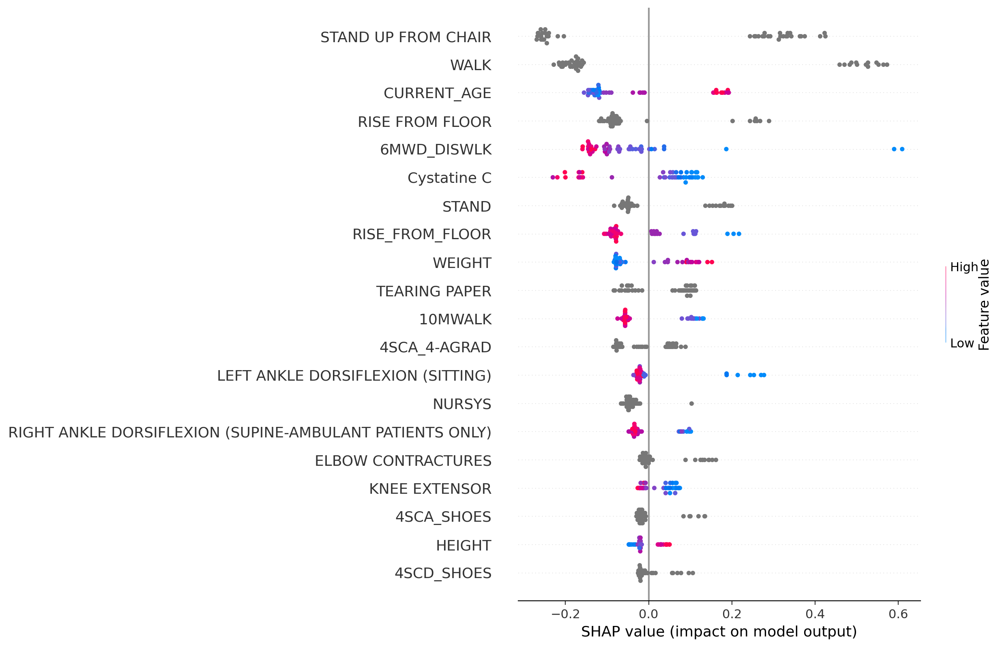

None
Regressor SHAP values


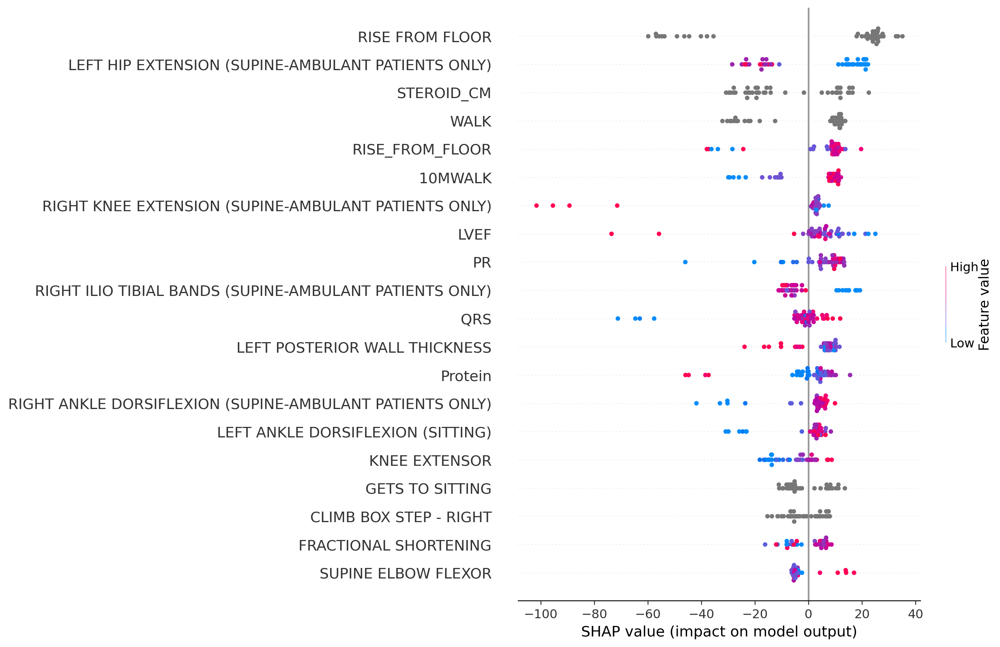

None


Micro-averaged classification report:
-------------------------------------
              precision    recall  f1-score   support

           0       0.87      0.90      0.89       167
           1       0.64      0.56      0.60        52

    accuracy                           0.82       219
   macro avg       0.76      0.73      0.74       219
weighted avg       0.81      0.82      0.82       219



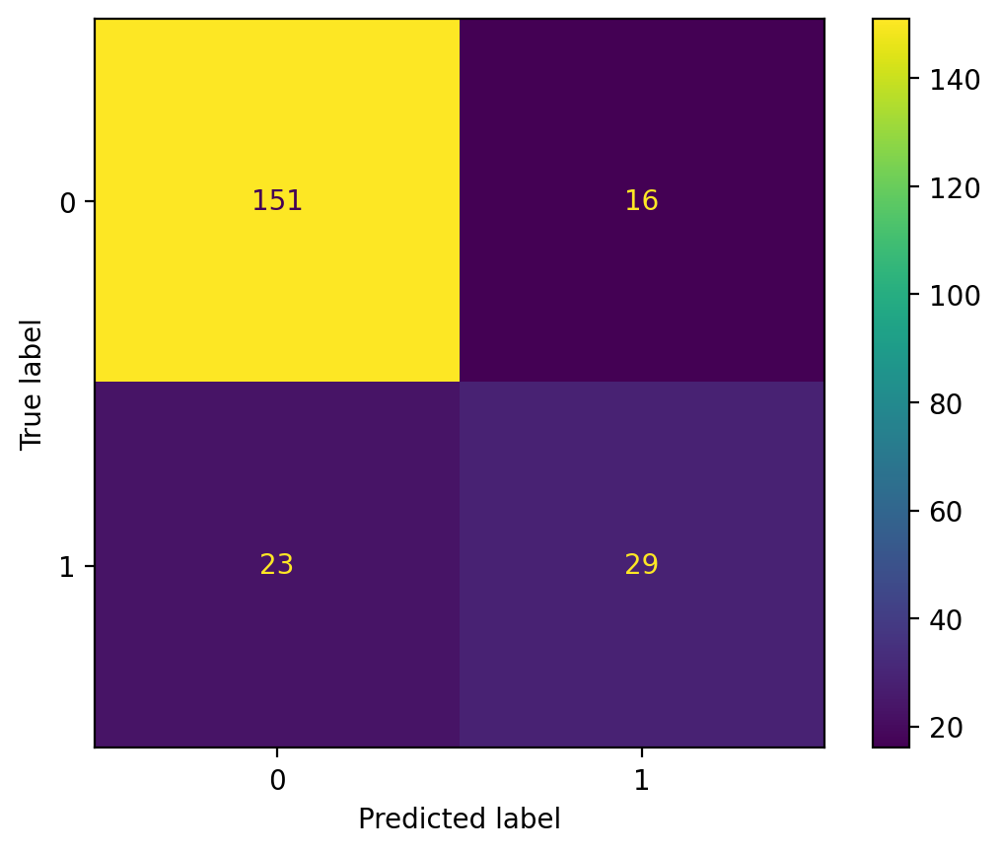

Time mean absolute error: 200.317



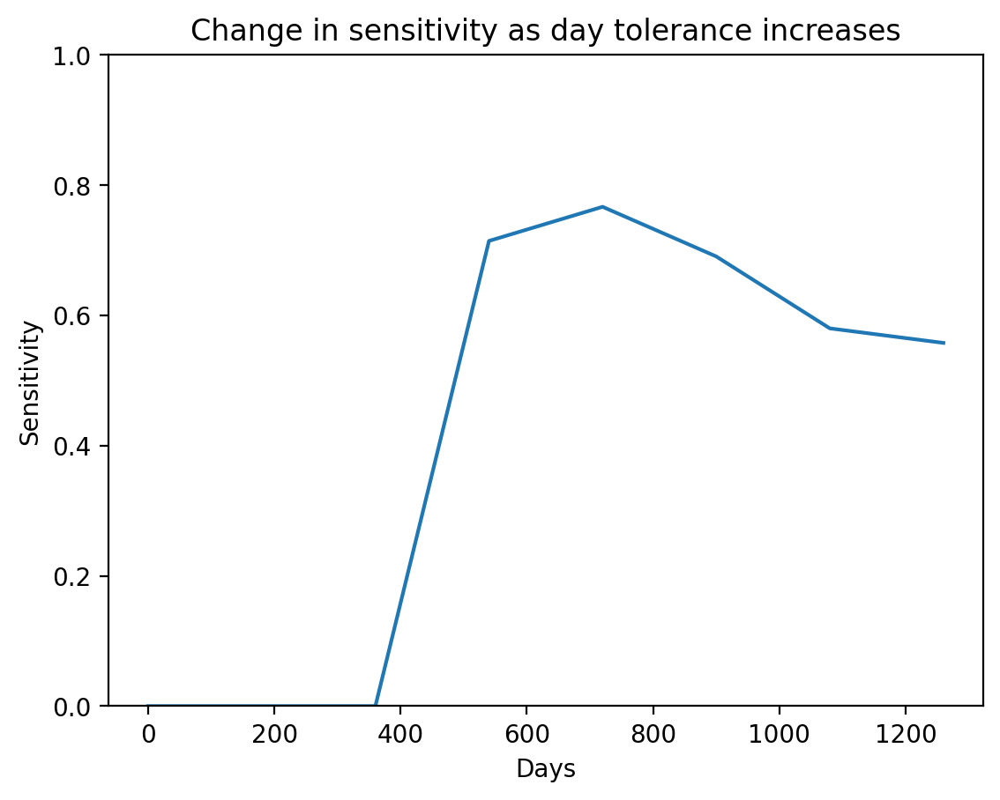

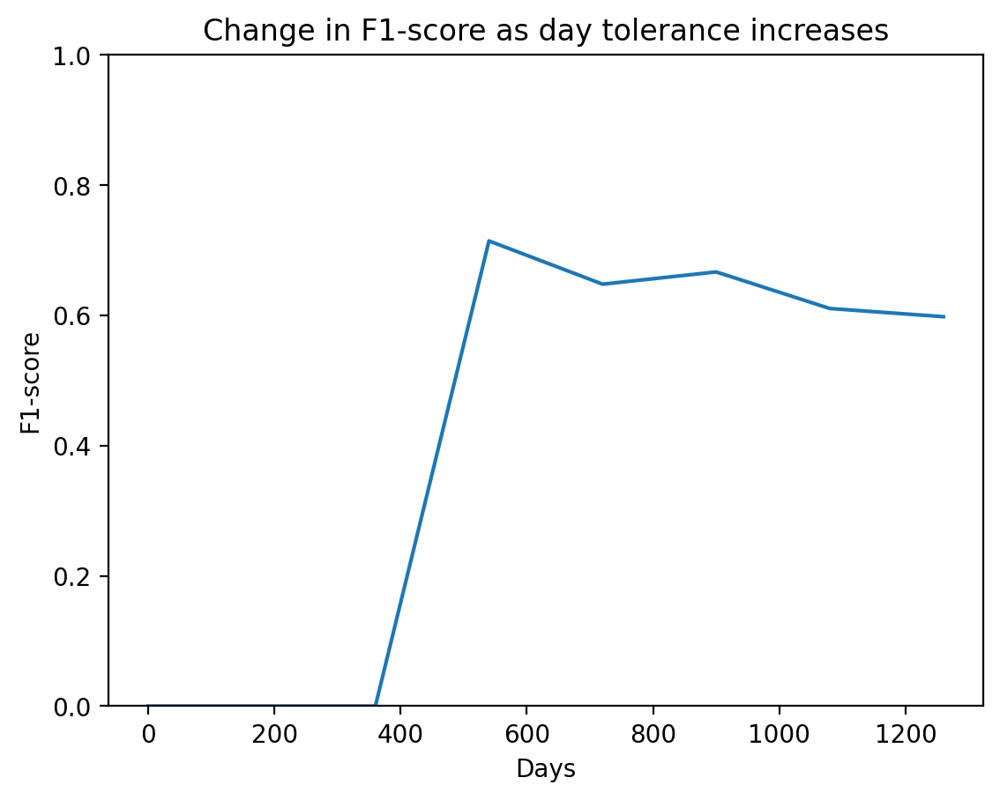

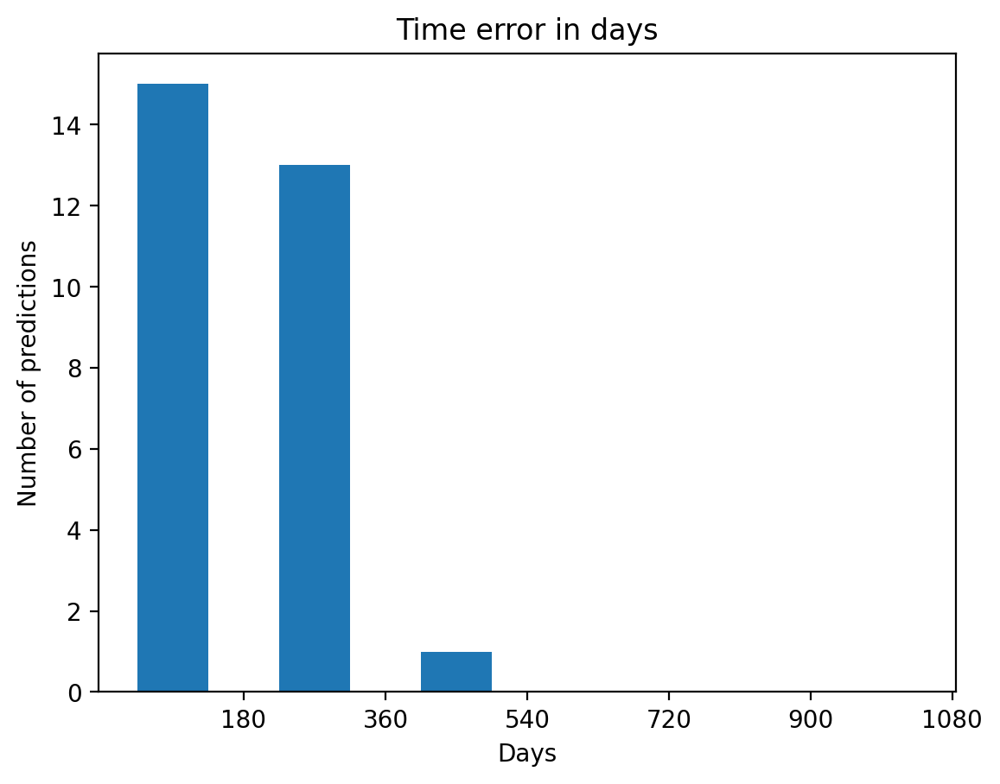

In [10]:
run_pipeline(unimputed_df_0, ['EVENT', 'TIME_IN_DAYS'], "catboost", folds, numerical_cols_to_impute)

### CoxPH with EN

Running fold 0 ...
0.6000000000000001


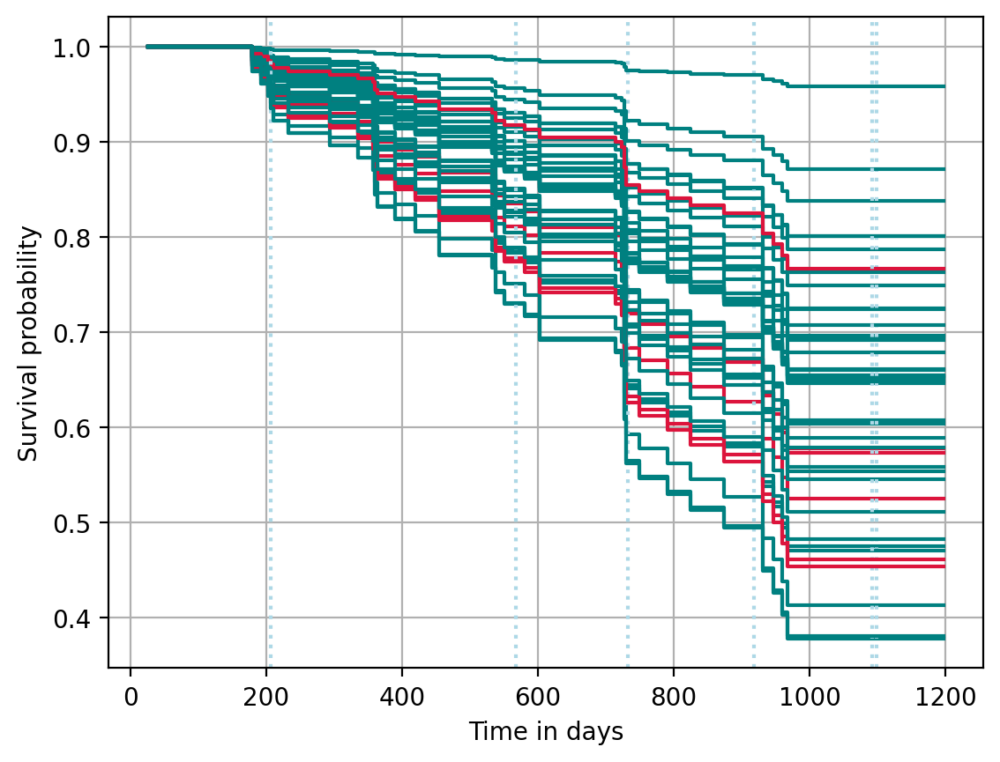

  0%|          | 0/44 [00:00<?, ?it/s]

coxph SHAP values


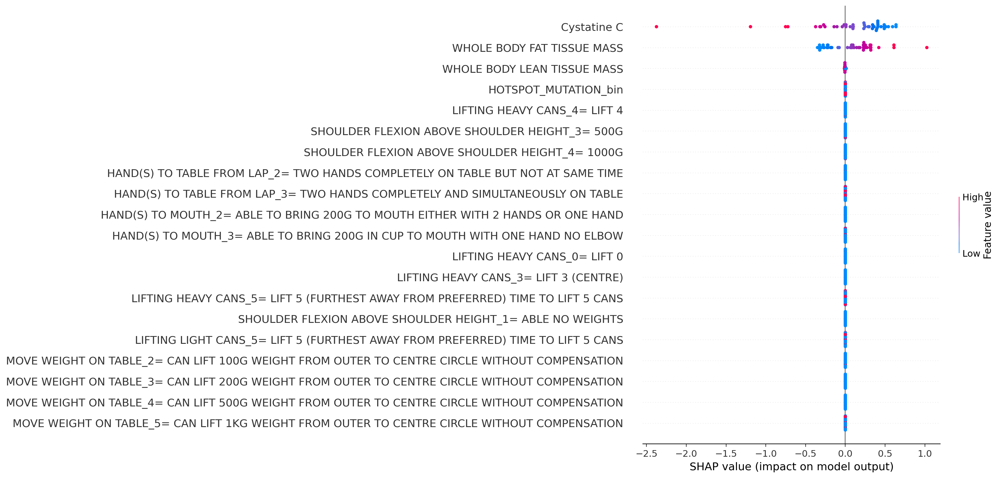

None
Running fold 1 ...
0.45


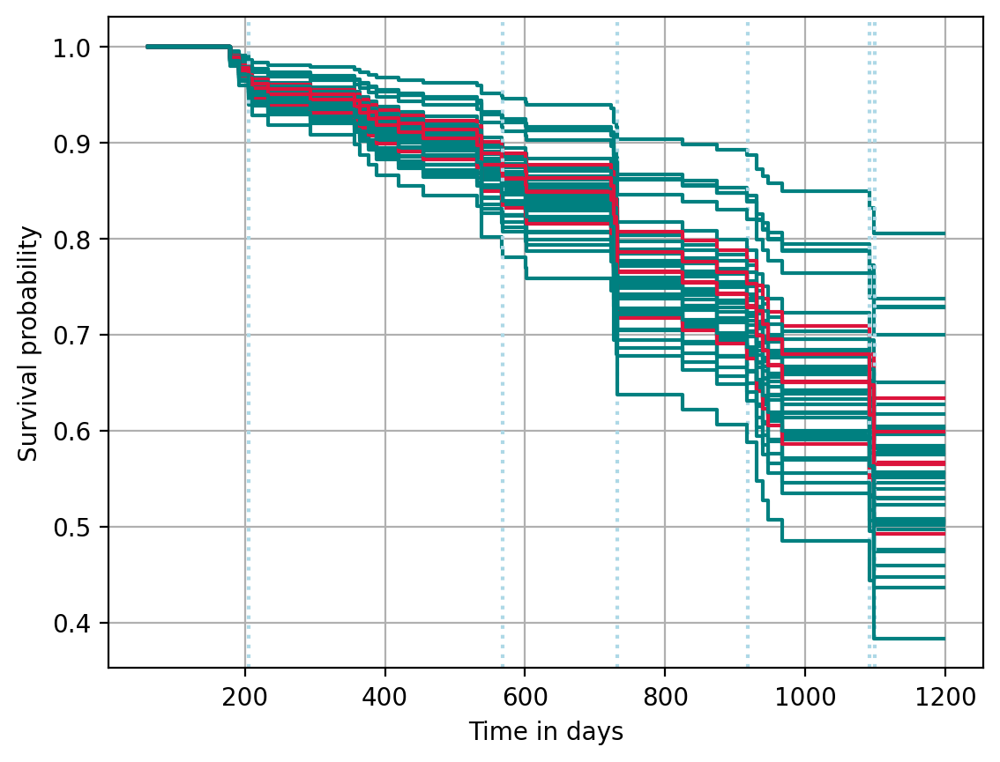

  0%|          | 0/44 [00:00<?, ?it/s]

coxph SHAP values


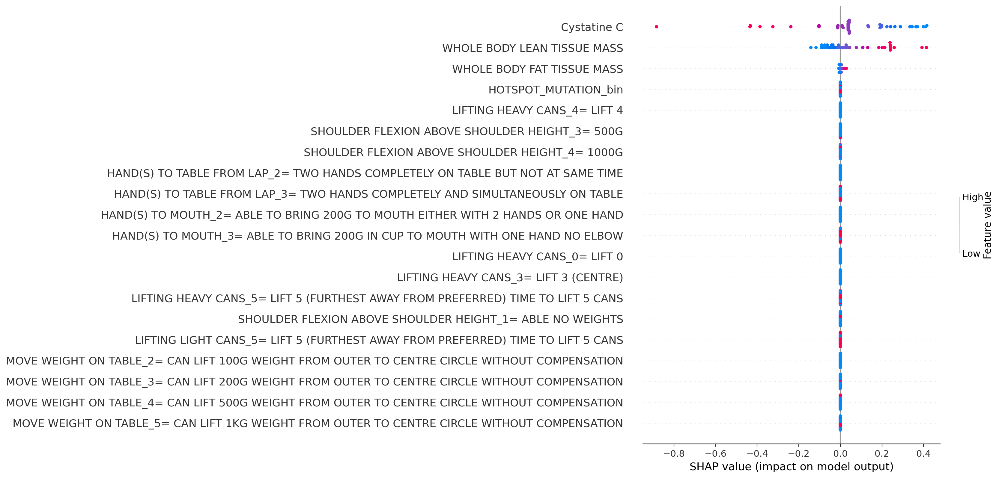

None
Running fold 2 ...
0.55


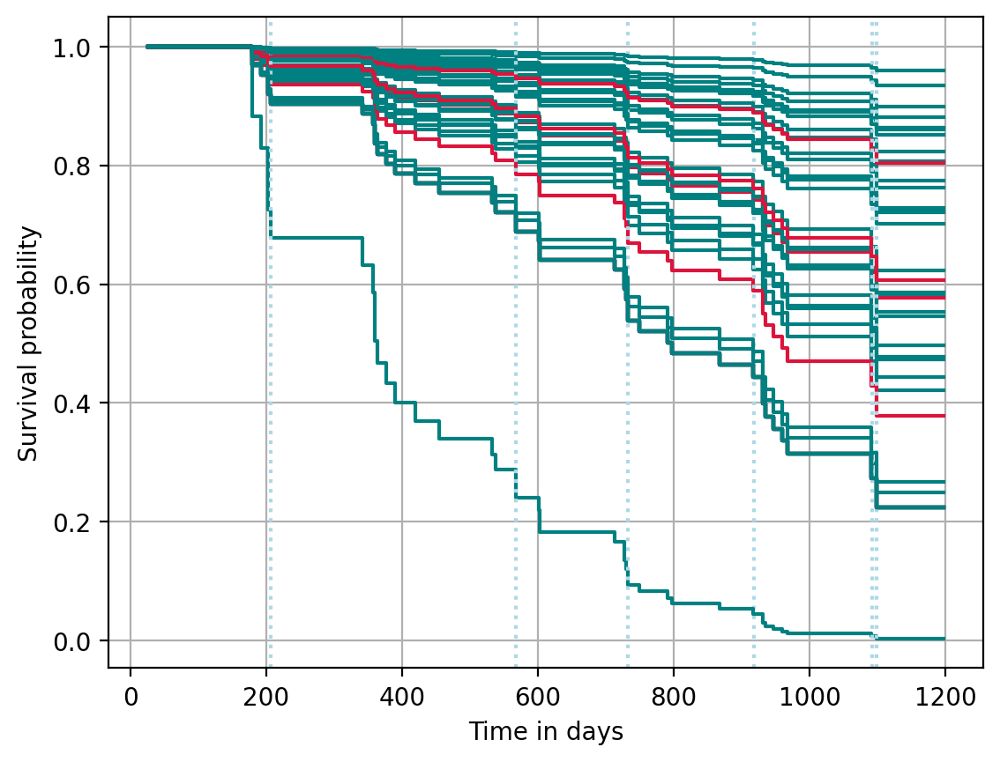

  0%|          | 0/44 [00:00<?, ?it/s]

coxph SHAP values


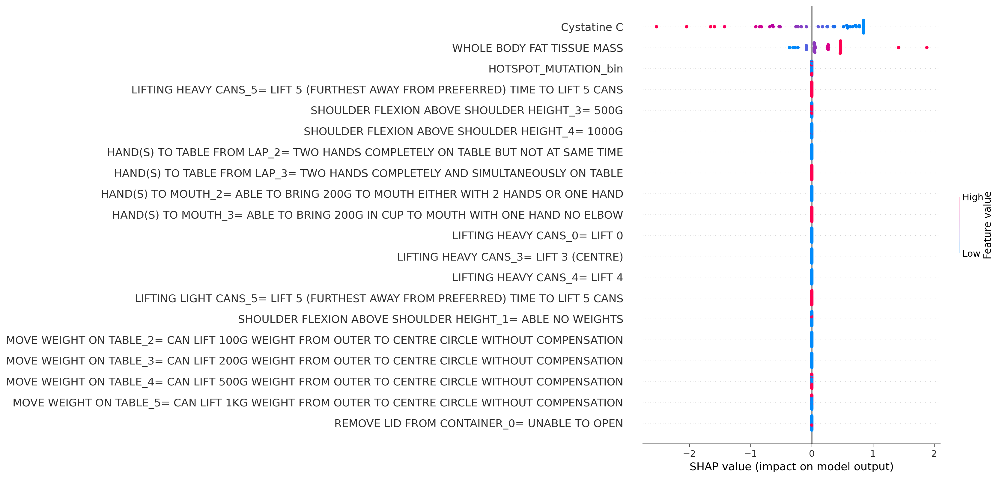

None
Running fold 3 ...
0.55


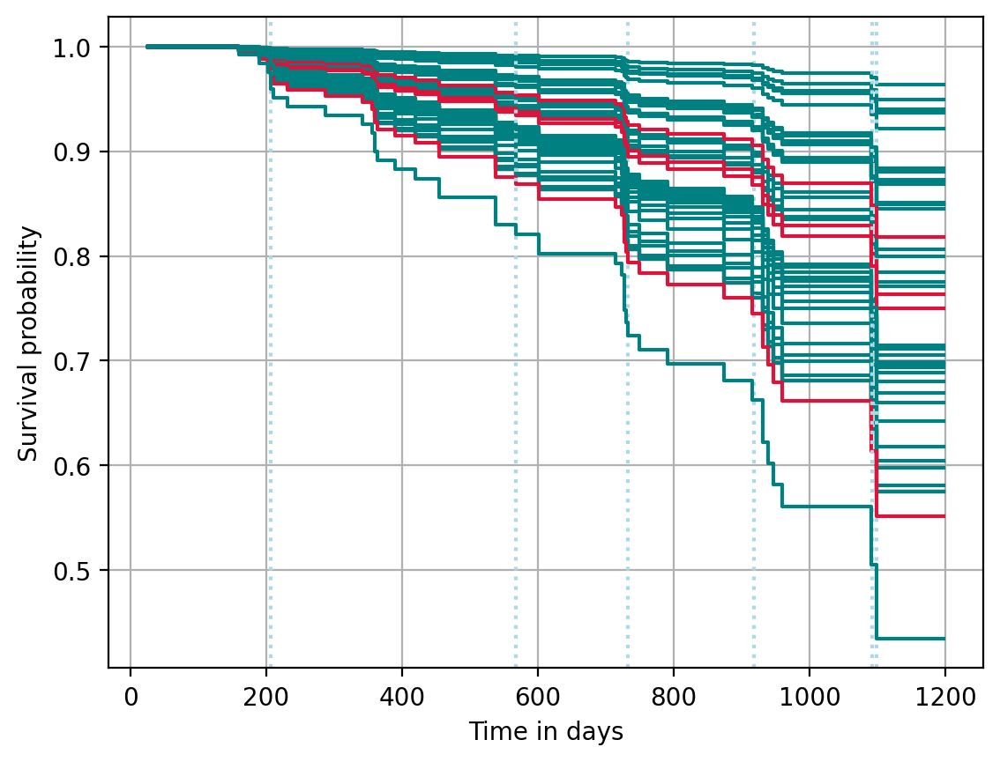

  0%|          | 0/44 [00:00<?, ?it/s]

coxph SHAP values


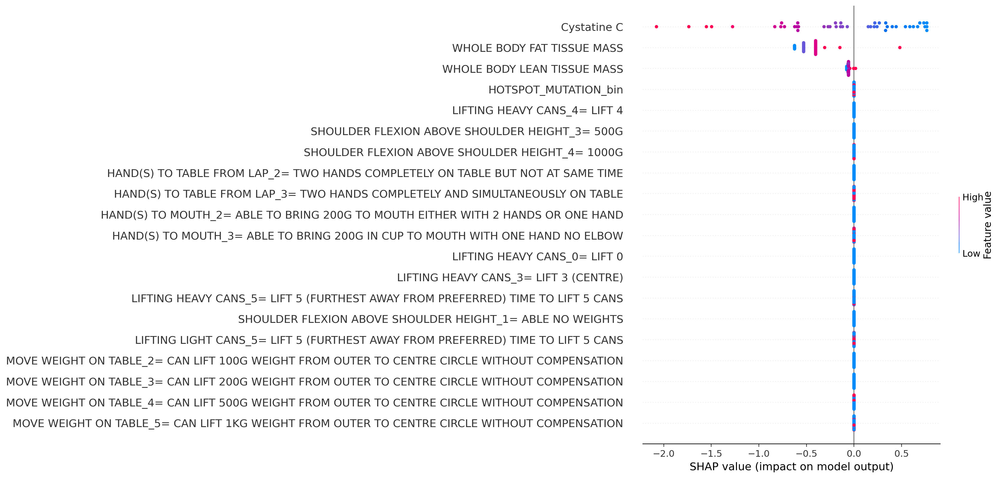

None
Running fold 4 ...
0.6000000000000001


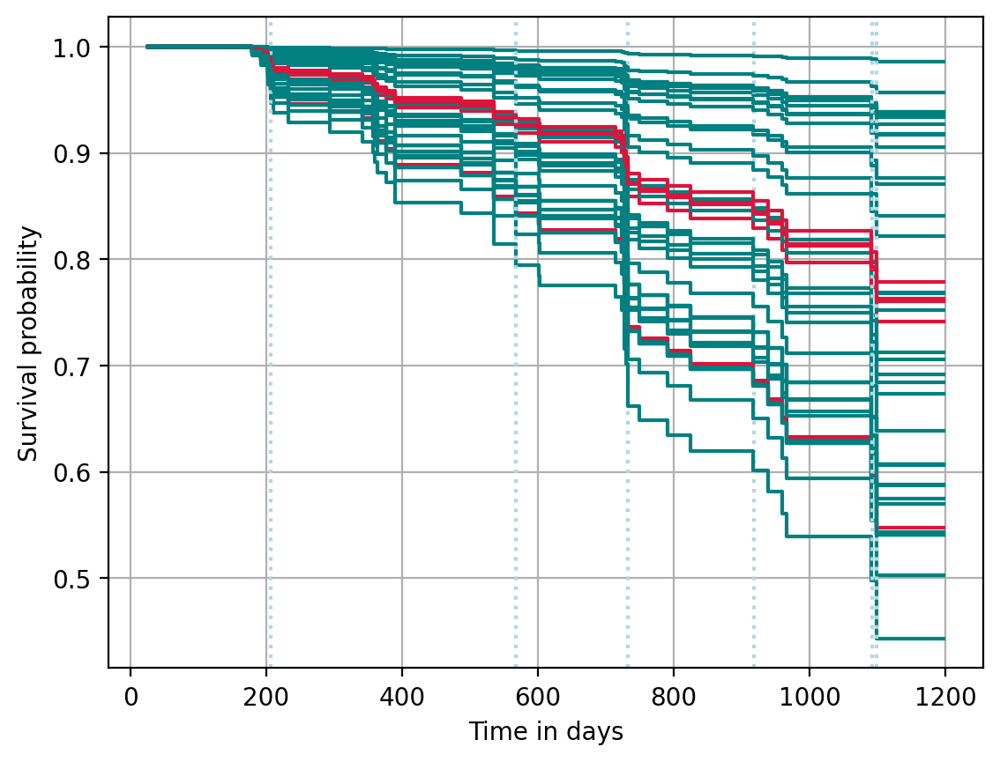

  0%|          | 0/43 [00:00<?, ?it/s]

coxph SHAP values


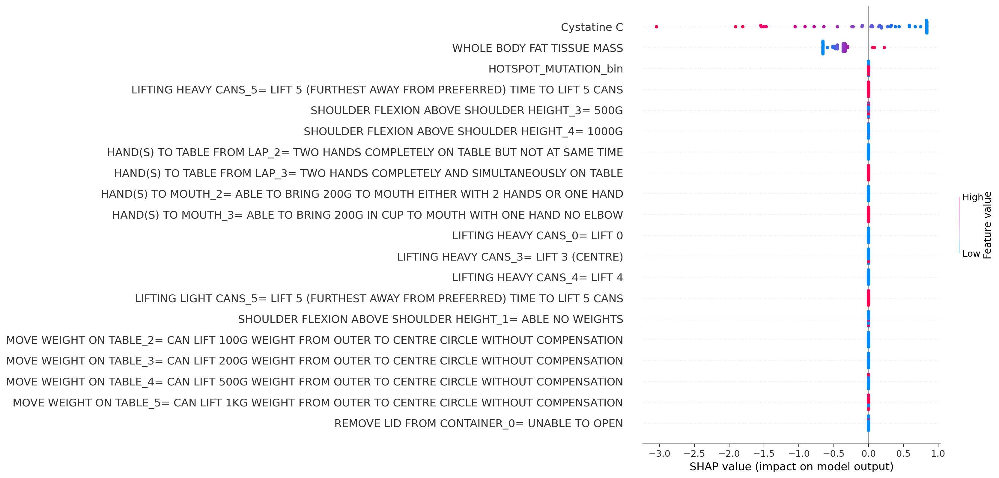

None


Micro-averaged classification report:
-------------------------------------
              precision    recall  f1-score   support

           0       0.82      0.81      0.82       167
           1       0.43      0.44      0.43        52

    accuracy                           0.73       219
   macro avg       0.63      0.63      0.63       219
weighted avg       0.73      0.73      0.73       219



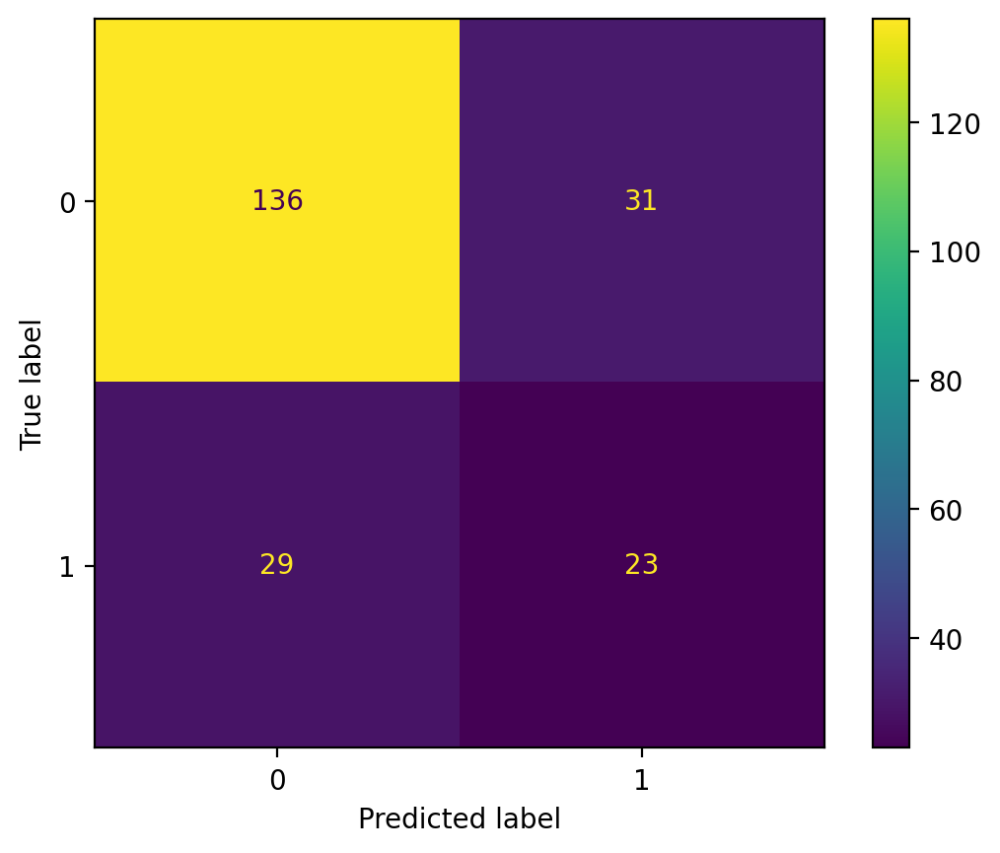

Time mean absolute error: 382.699



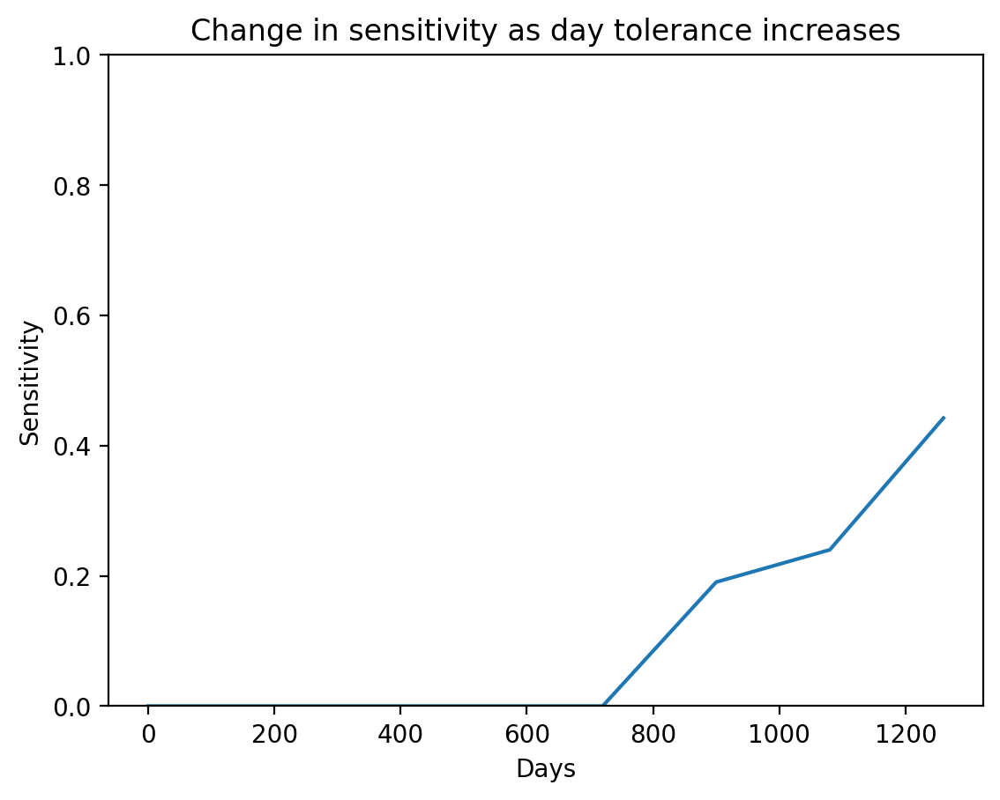

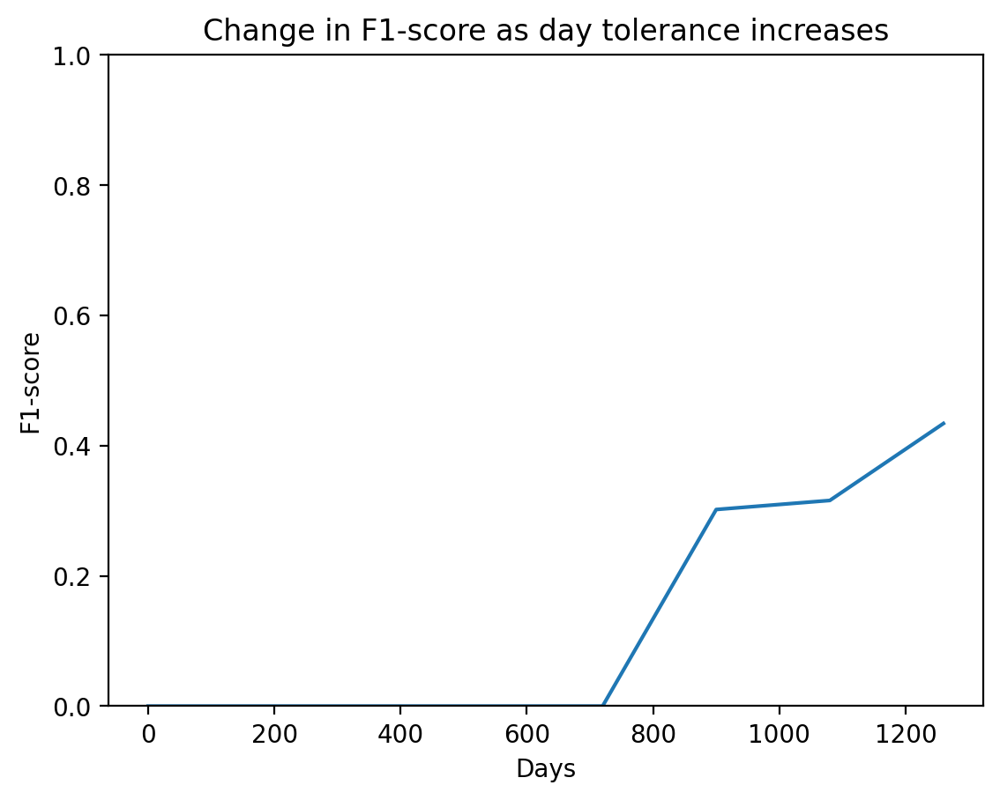

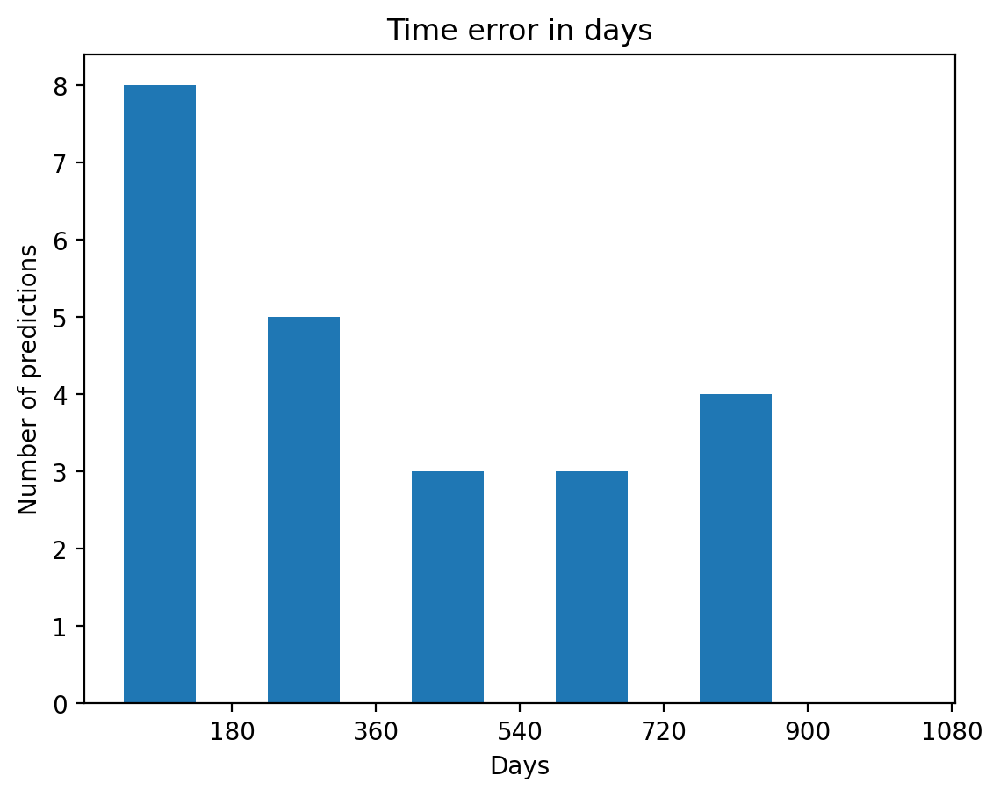

C-Index Censored:
-----------------
Fold 0
Concordance Index: 0.810
Number of concordant pairs: 201
Number of diconcordant pairs: 47
Fold 1
Concordance Index: 0.725
Number of concordant pairs: 235
Number of diconcordant pairs: 89
Fold 2
Concordance Index: 0.585
Number of concordant pairs: 186
Number of diconcordant pairs: 129
Fold 3
Concordance Index: 0.635
Number of concordant pairs: 190
Number of diconcordant pairs: 109
Fold 4
Concordance Index: 0.494
Number of concordant pairs: 128
Number of diconcordant pairs: 131
Macro-average Concordance Index: 0.650


C-Index IPCW:
-------------
Fold 0
IPCW Concordance Index: 0.571
Number of concordant pairs: 201
Number of diconcordant pairs: 47
Fold 1
IPCW Concordance Index: 0.757
Number of concordant pairs: 235
Number of diconcordant pairs: 89
Fold 2
IPCW Concordance Index: 0.598
Number of concordant pairs: 186
Number of diconcordant pairs: 129
Fold 3
IPCW Concordance Index: 0.661
Number of concordant pairs: 190
Number of diconcordant pairs: 1

In [11]:
run_pipeline(
    encoded_unimputed_df_0.drop(columns=categorical_cols), 
    ['EVENT', 'TIME_IN_DAYS'], 
    "coxph", 
    folds, 
    numerical_cols_to_impute
)

### RSF

Running fold 0 ...
0.5


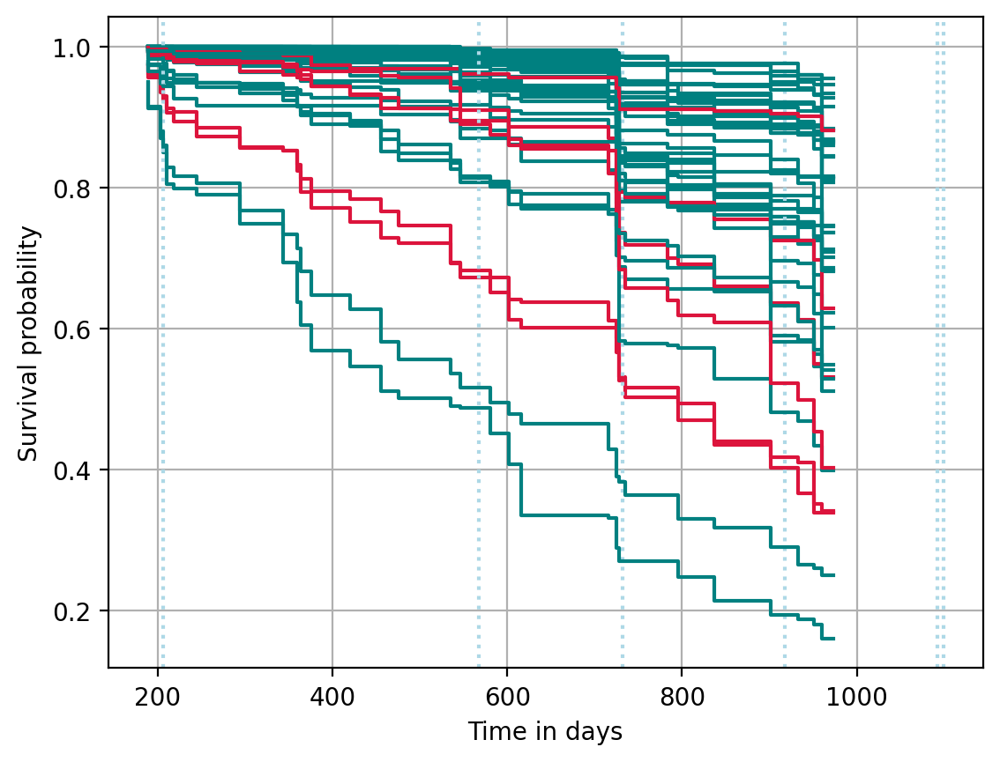

  0%|          | 0/44 [00:00<?, ?it/s]

rsf SHAP values


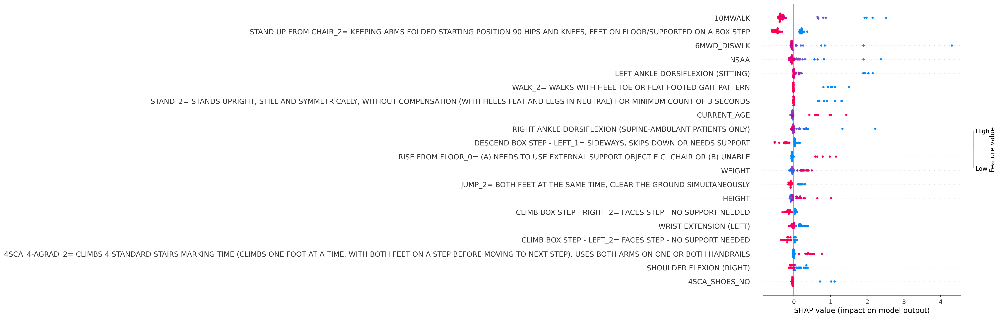

None
Running fold 1 ...
0.55


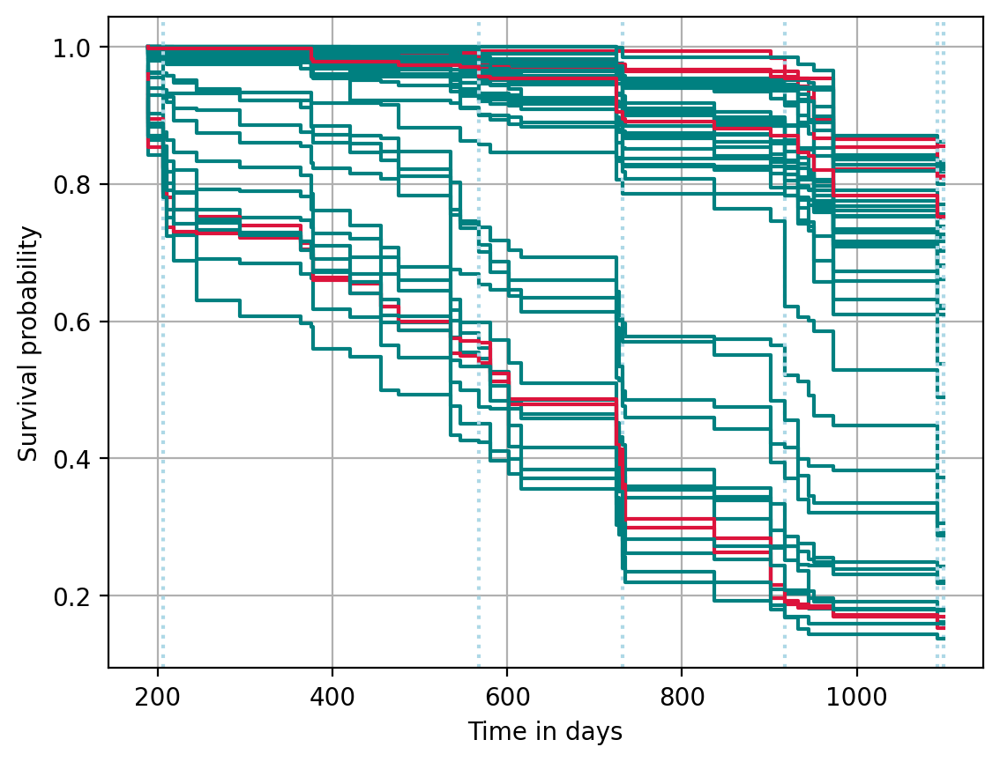

  0%|          | 0/44 [00:00<?, ?it/s]

rsf SHAP values


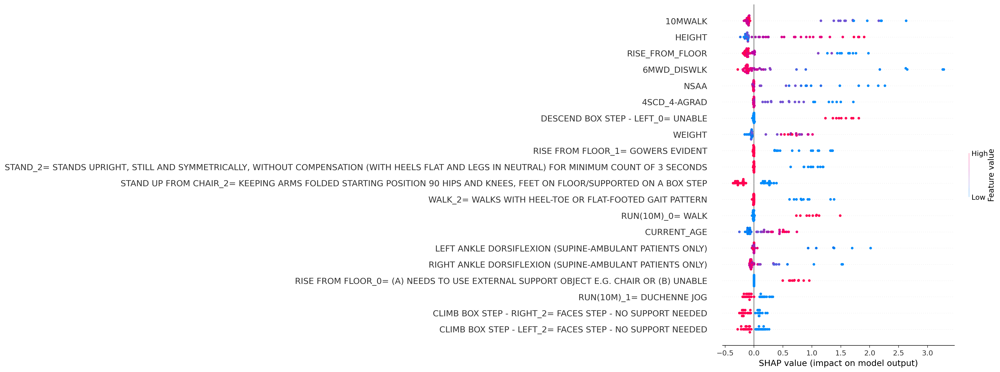

None
Running fold 2 ...
0.6


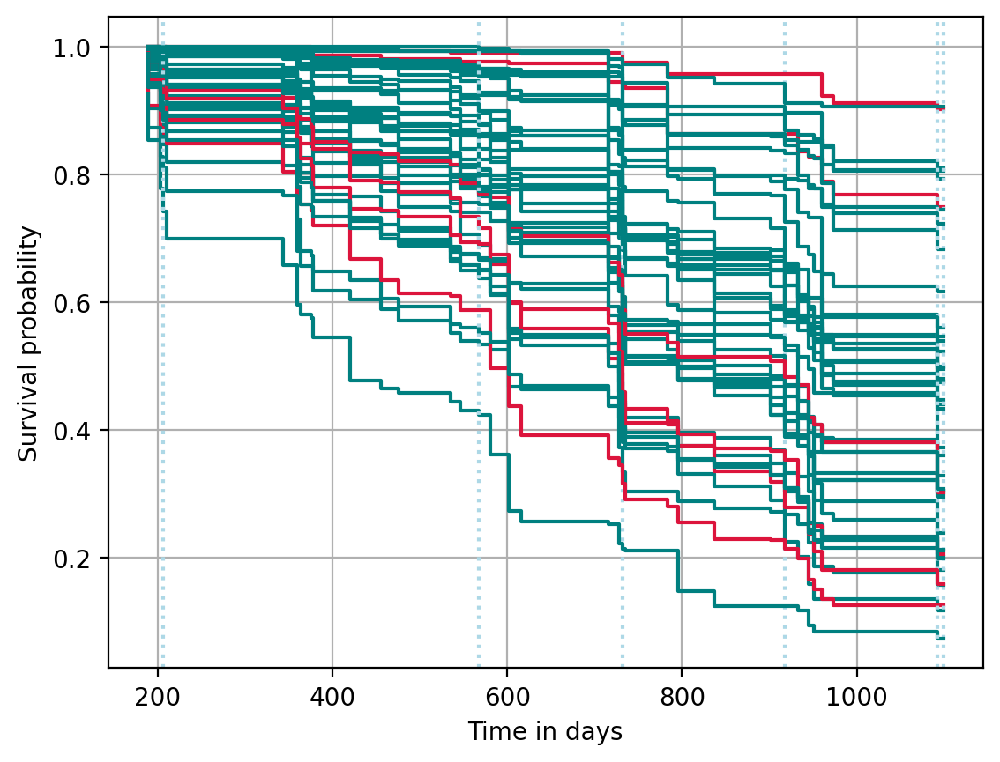

  0%|          | 0/44 [00:00<?, ?it/s]

rsf SHAP values


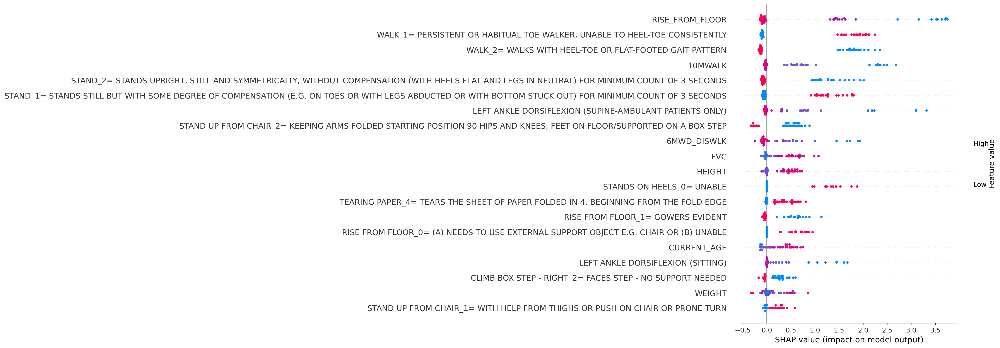

None
Running fold 3 ...
0.55


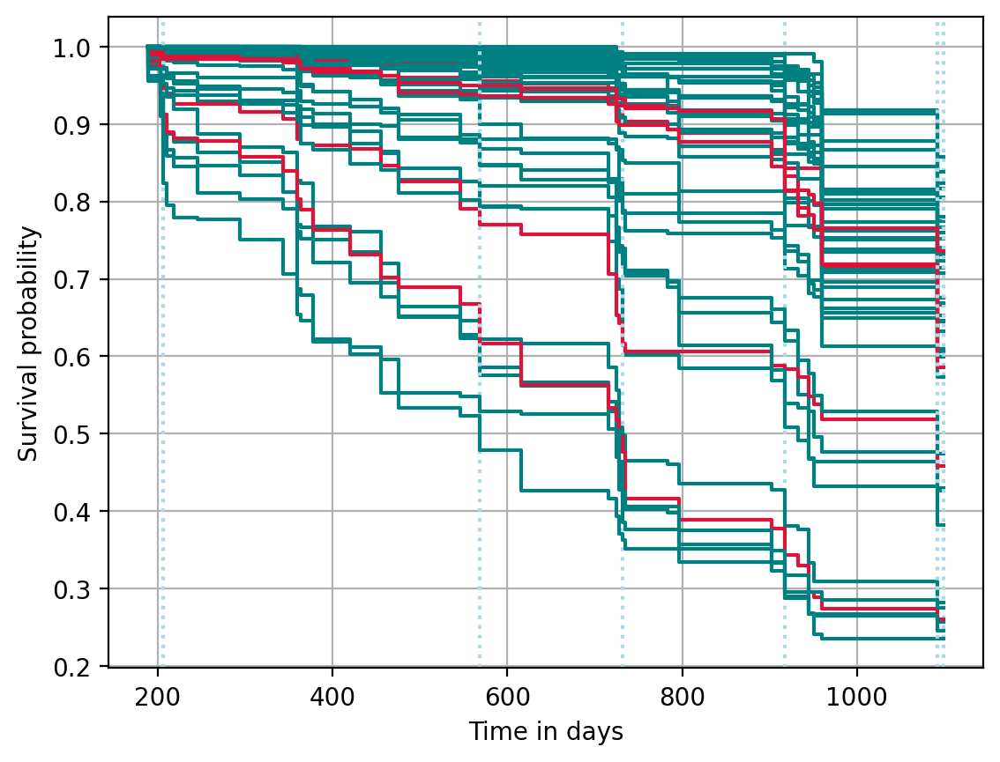

  0%|          | 0/44 [00:00<?, ?it/s]

rsf SHAP values


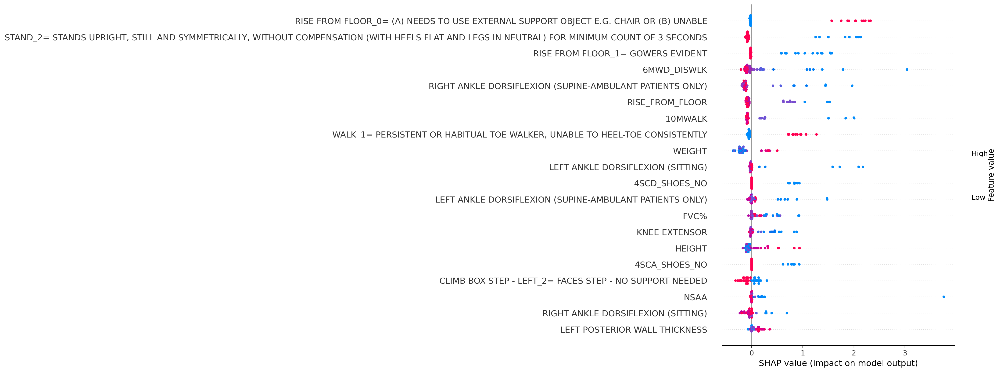

None
Running fold 4 ...
0.55


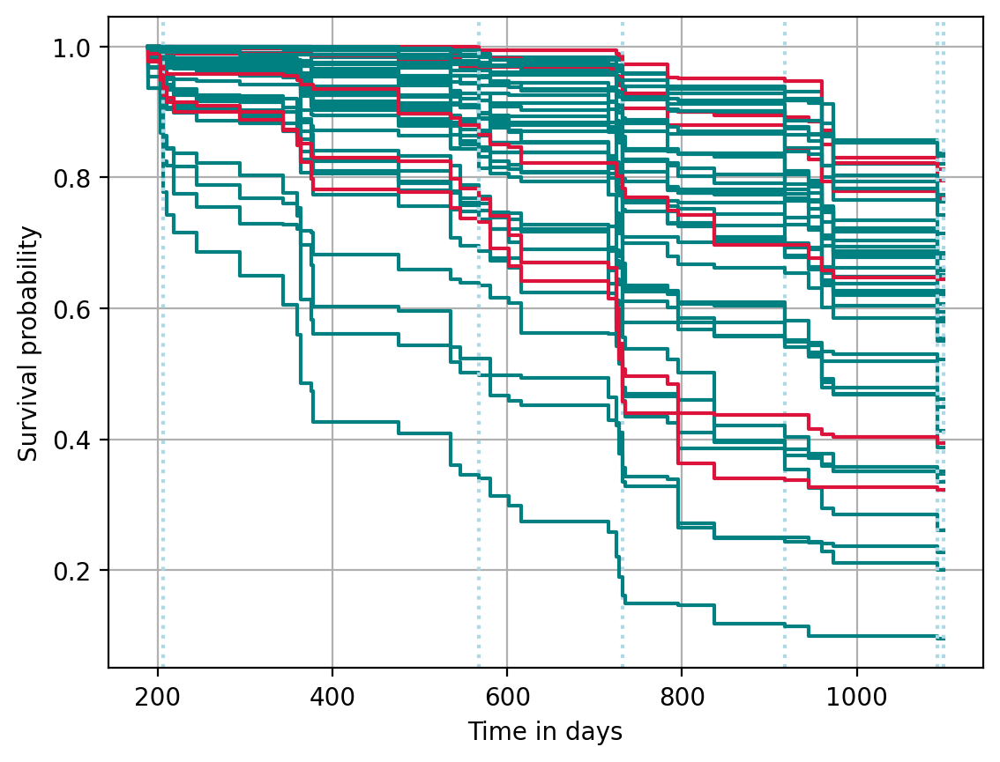

  0%|          | 0/43 [00:00<?, ?it/s]

rsf SHAP values


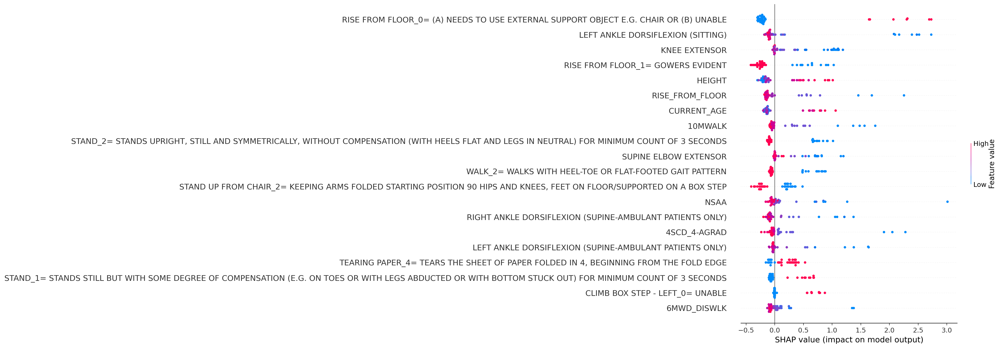

None


Micro-averaged classification report:
-------------------------------------
              precision    recall  f1-score   support

           0       0.93      0.76      0.84       167
           1       0.51      0.81      0.63        52

    accuracy                           0.77       219
   macro avg       0.72      0.78      0.73       219
weighted avg       0.83      0.77      0.79       219



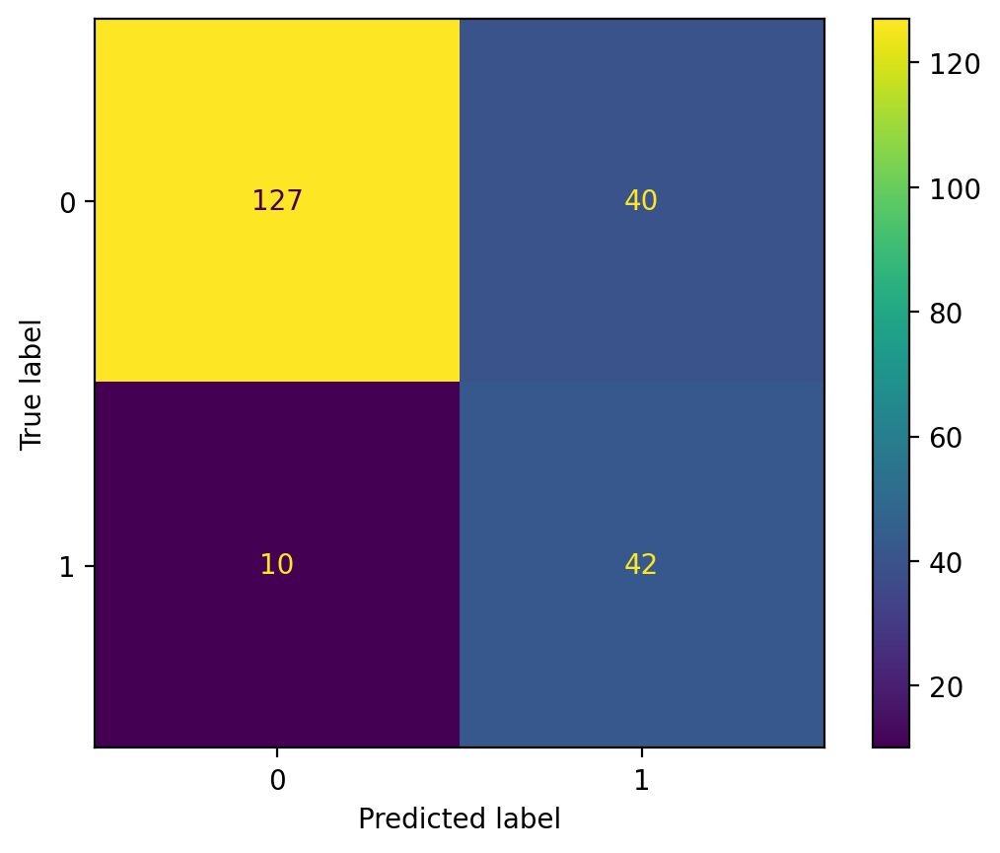

Time mean absolute error: 224.717



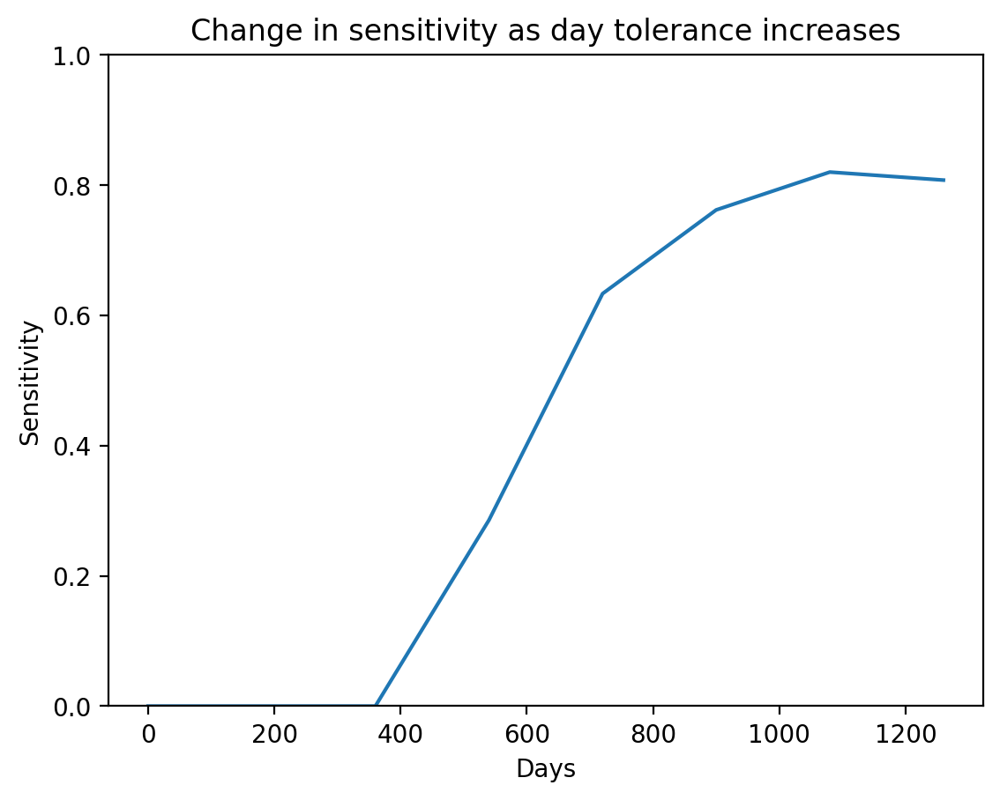

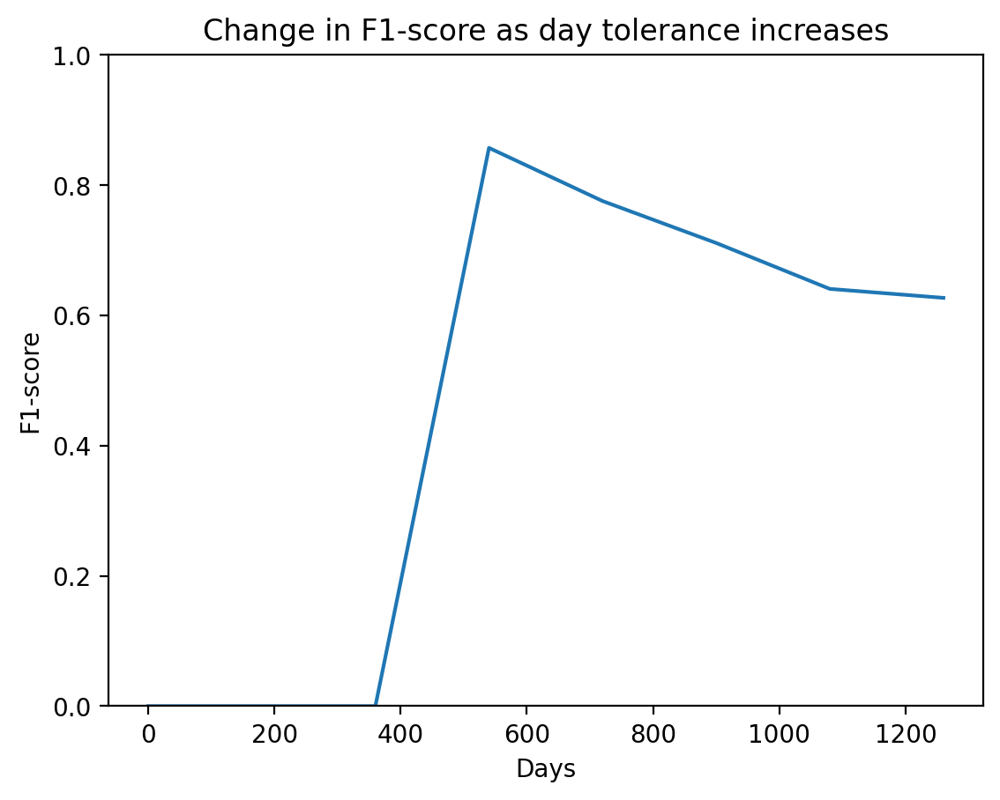

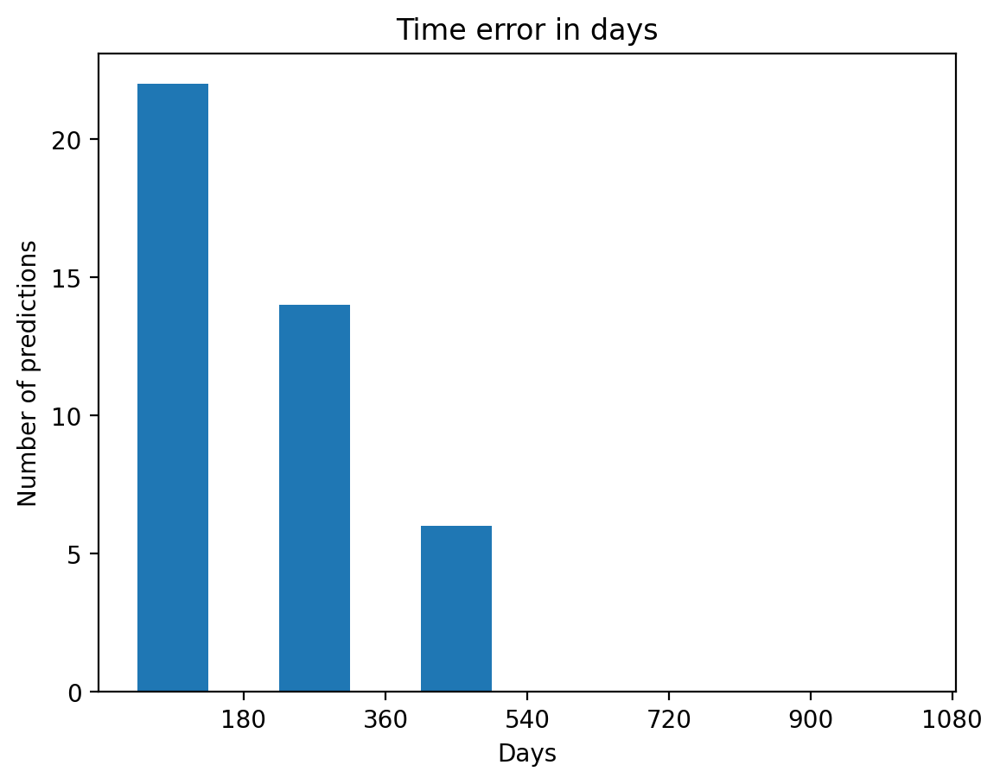

C-Index Censored:
-----------------
Fold 0
Concordance Index: 0.919
Number of concordant pairs: 228
Number of diconcordant pairs: 20
Fold 1
Concordance Index: 0.920
Number of concordant pairs: 298
Number of diconcordant pairs: 26
Fold 2
Concordance Index: 0.920
Number of concordant pairs: 309
Number of diconcordant pairs: 27
Fold 3
Concordance Index: 0.863
Number of concordant pairs: 259
Number of diconcordant pairs: 41
Fold 4
Concordance Index: 0.946
Number of concordant pairs: 245
Number of diconcordant pairs: 14
Macro-average Concordance Index: 0.914


C-Index IPCW:
-------------
Fold 0
IPCW Concordance Index: 0.836
Number of concordant pairs: 228
Number of diconcordant pairs: 20
Fold 1
IPCW Concordance Index: 0.875
Number of concordant pairs: 298
Number of diconcordant pairs: 26
Fold 2
IPCW Concordance Index: 0.915
Number of concordant pairs: 309
Number of diconcordant pairs: 27
Fold 3
IPCW Concordance Index: 0.728
Number of concordant pairs: 259
Number of diconcordant pairs: 41
Fo

In [12]:
run_pipeline(encoded_unimputed_df_0.drop(columns=categorical_cols), 
    ['EVENT', 'TIME_IN_DAYS'], 
    "rsf", 
    folds, 
    numerical_cols_to_impute
            )

### GBSA

Running fold 0 ...
0.6


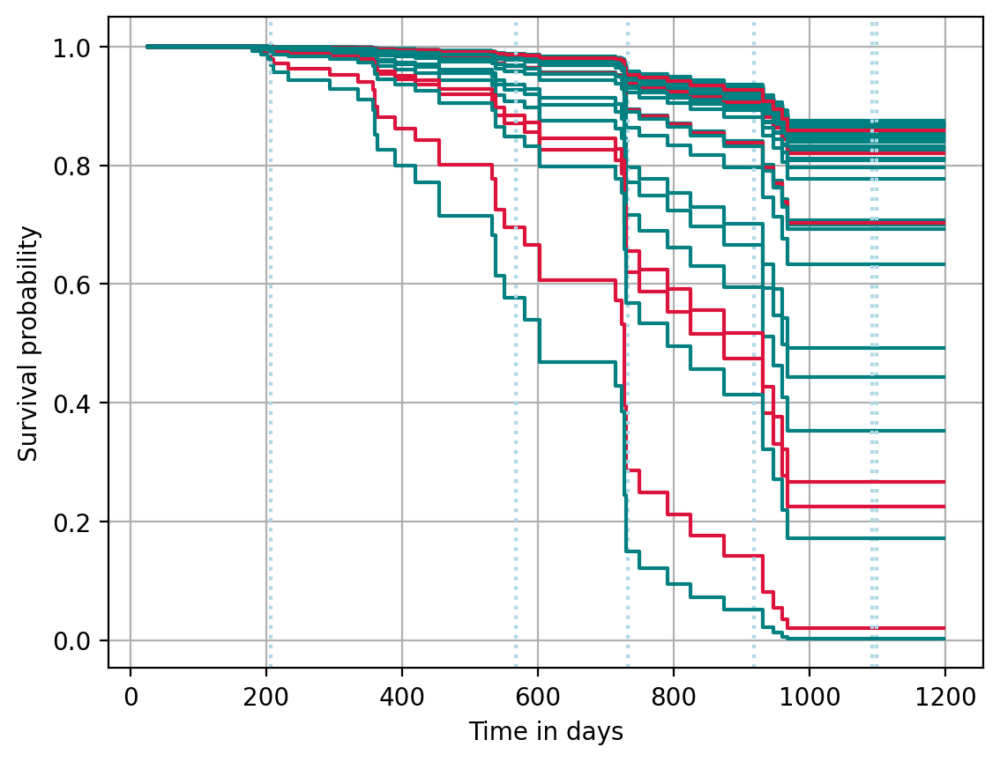

  0%|          | 0/44 [00:00<?, ?it/s]

gbsa SHAP values


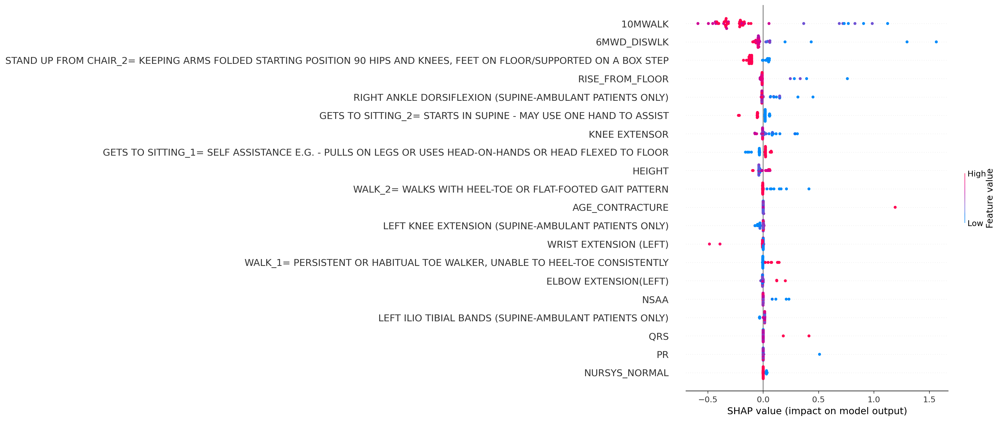

None
Running fold 1 ...
0.5


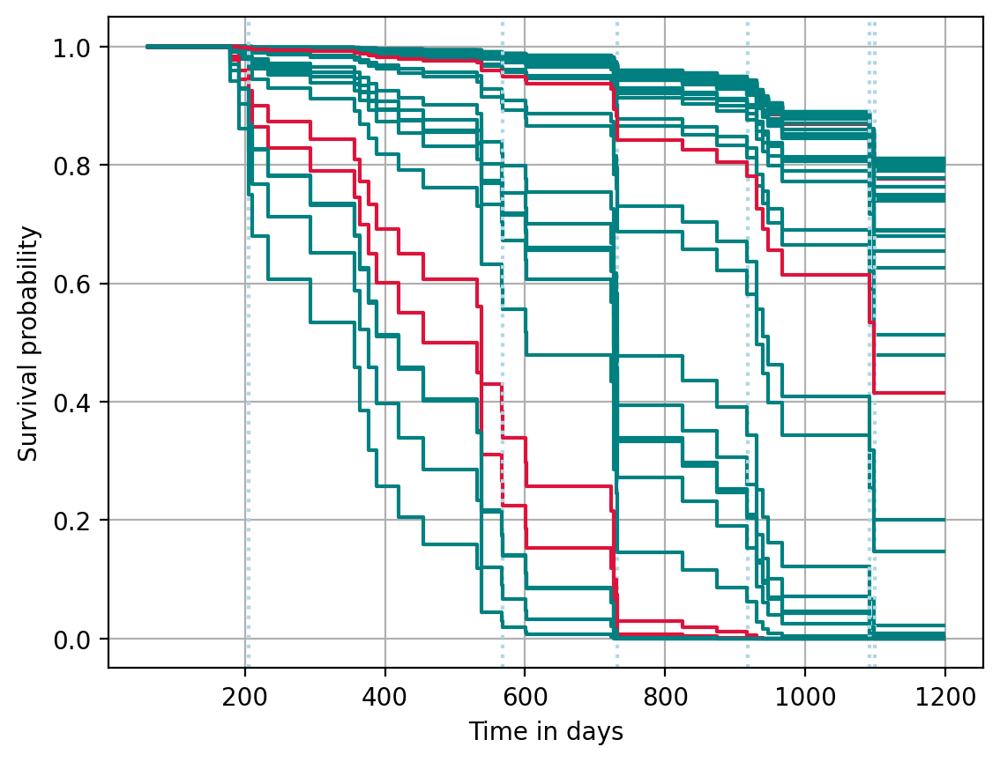

  0%|          | 0/44 [00:00<?, ?it/s]

gbsa SHAP values


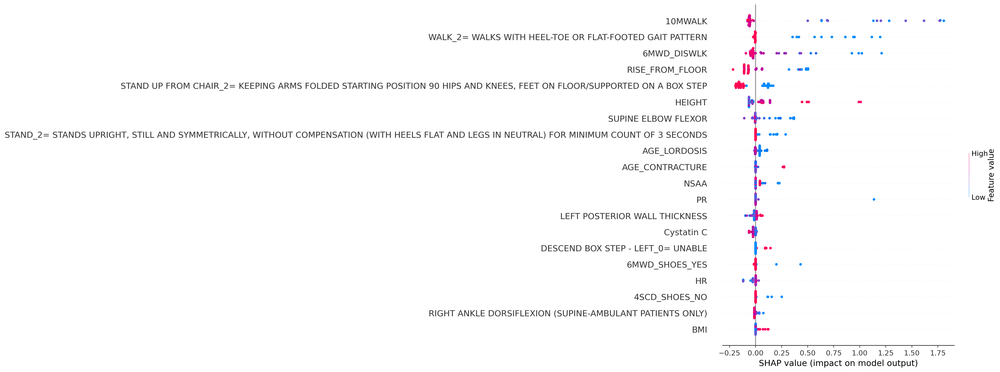

None
Running fold 2 ...
0.65


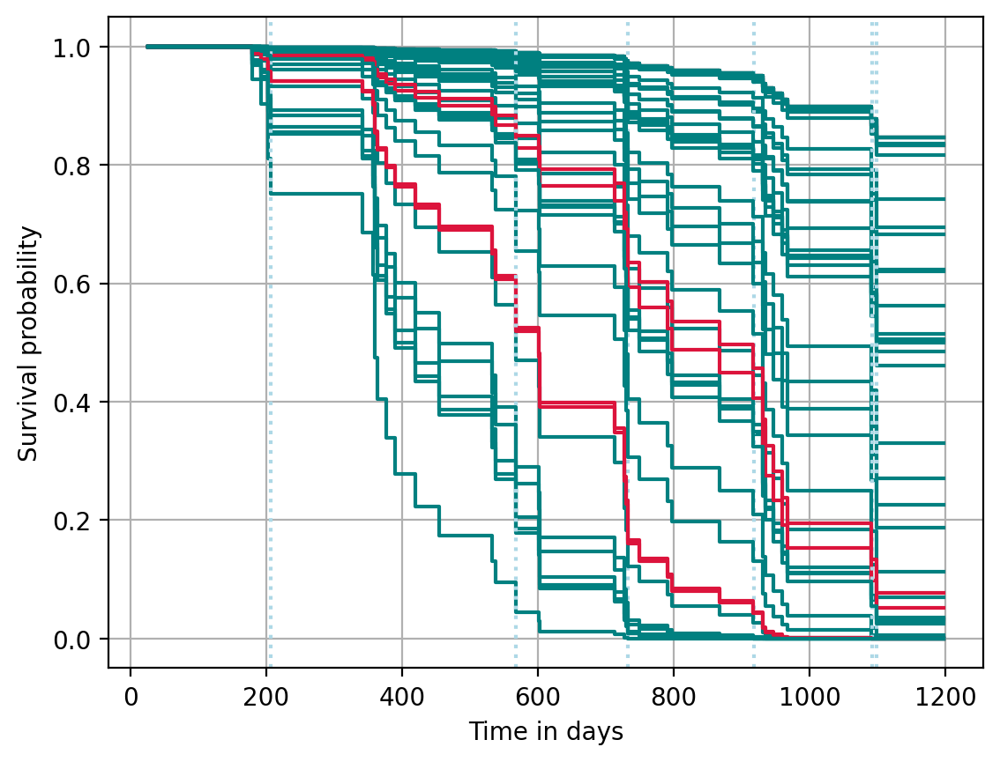

  0%|          | 0/44 [00:00<?, ?it/s]

gbsa SHAP values


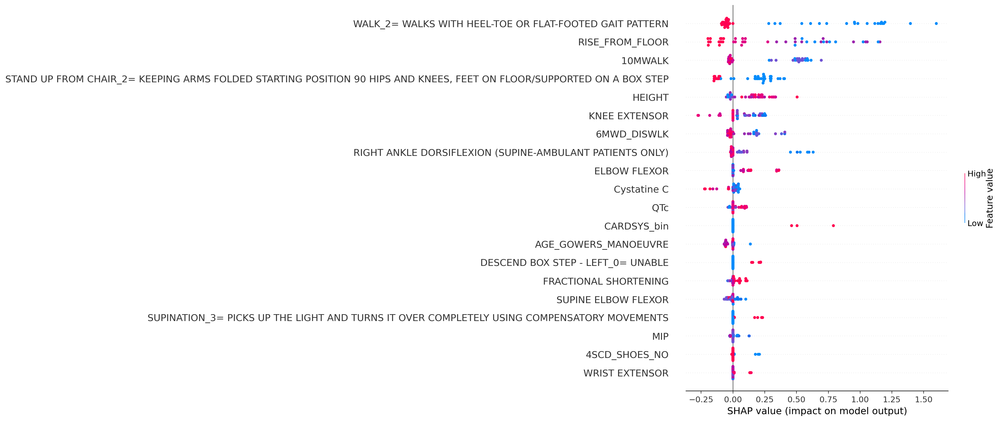

None
Running fold 3 ...
0.5


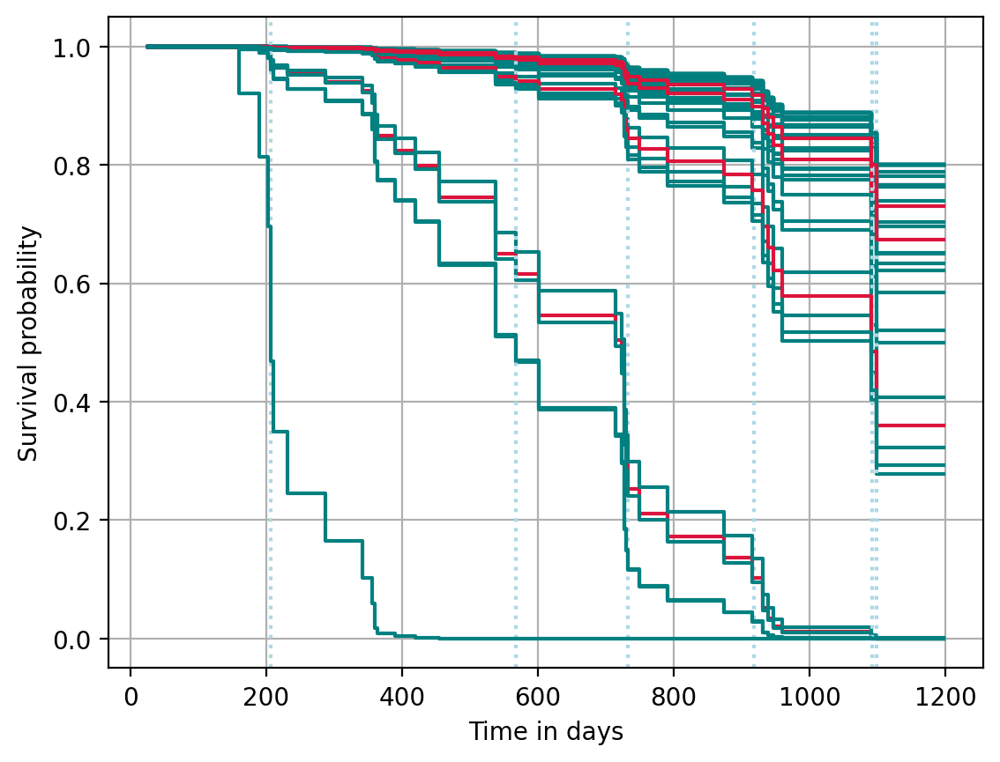

  0%|          | 0/44 [00:00<?, ?it/s]

gbsa SHAP values


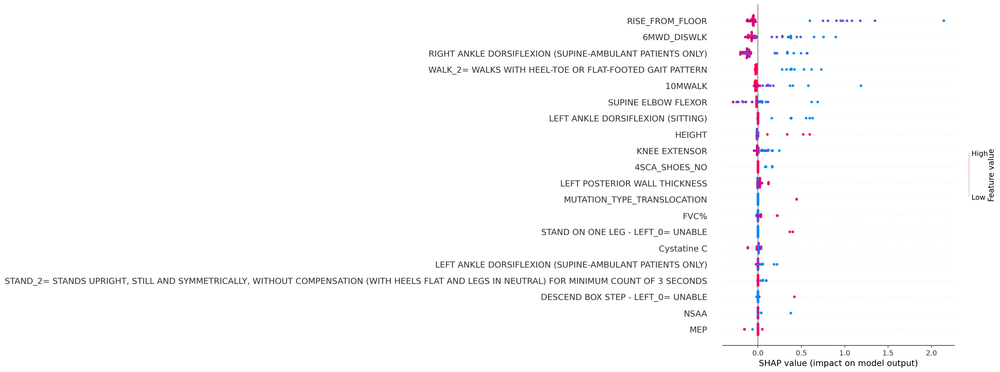

None
Running fold 4 ...
0.6


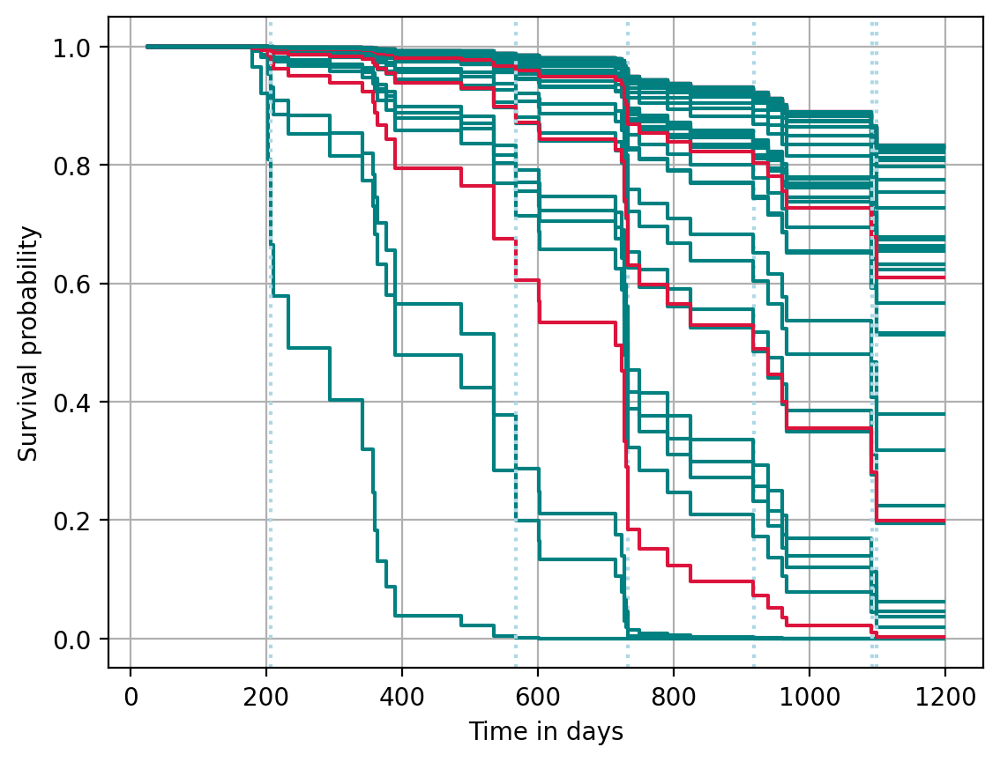

  0%|          | 0/43 [00:00<?, ?it/s]

gbsa SHAP values


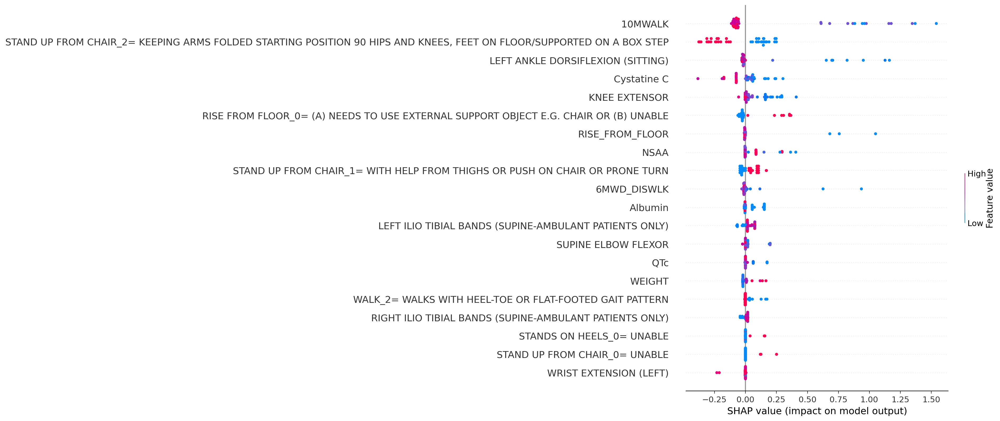

None


Micro-averaged classification report:
-------------------------------------
              precision    recall  f1-score   support

           0       0.93      0.75      0.83       167
           1       0.50      0.81      0.62        52

    accuracy                           0.76       219
   macro avg       0.71      0.78      0.72       219
weighted avg       0.82      0.76      0.78       219



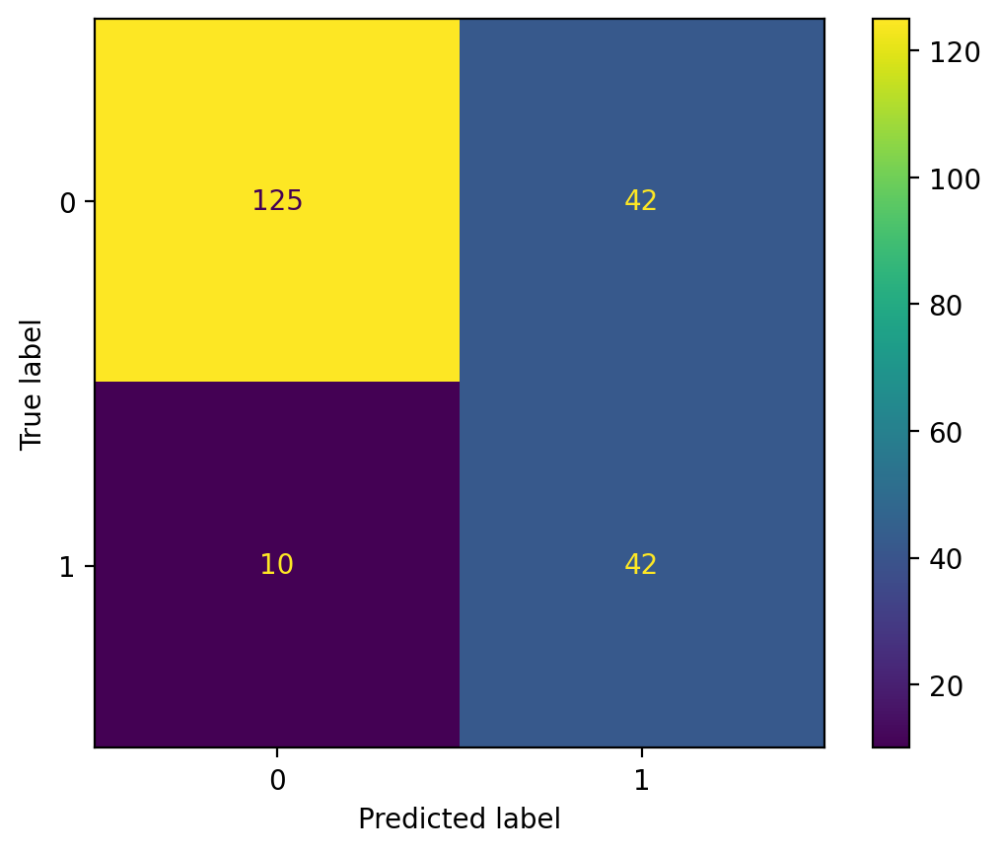

Time mean absolute error: 255.883



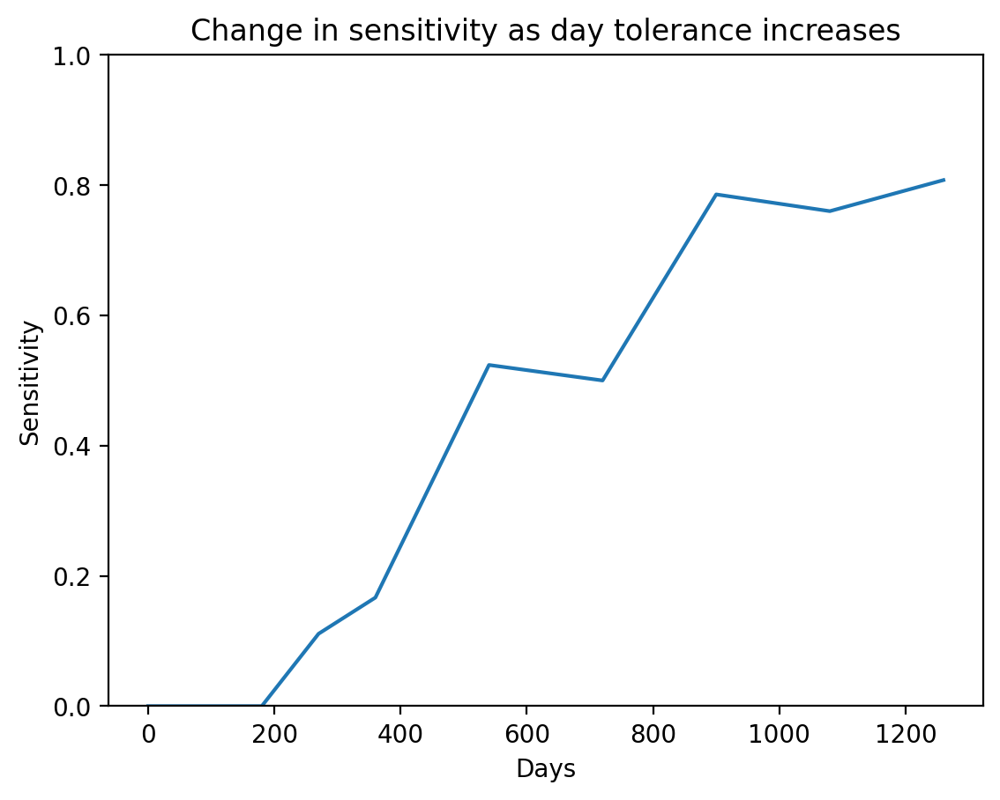

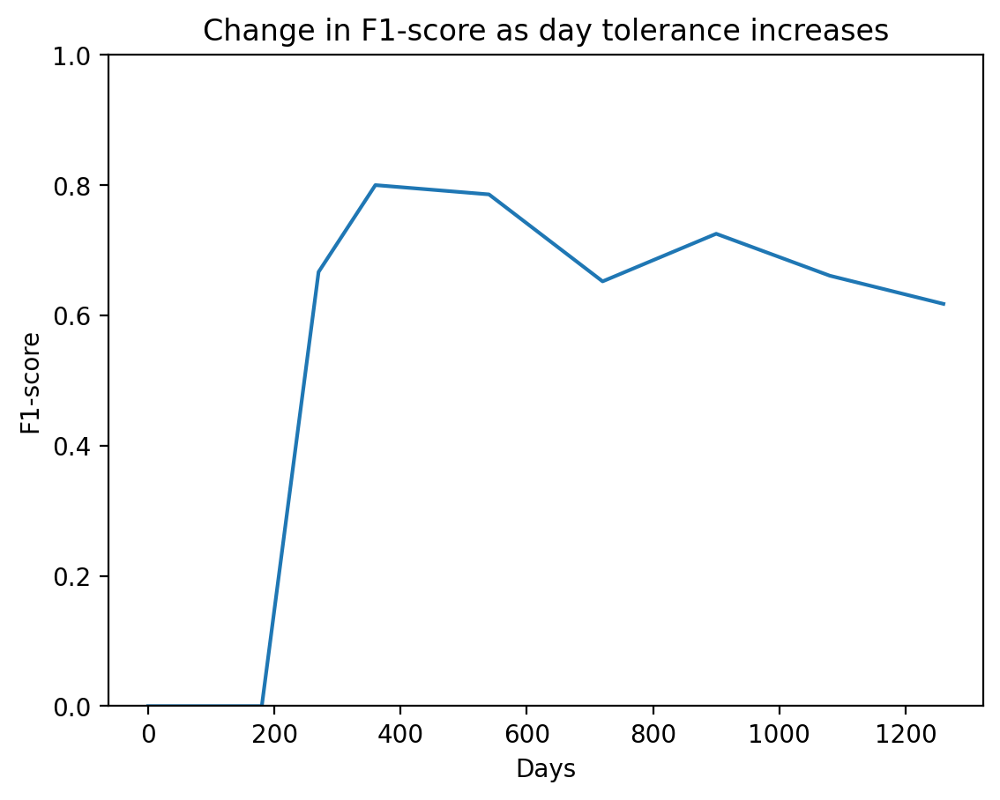

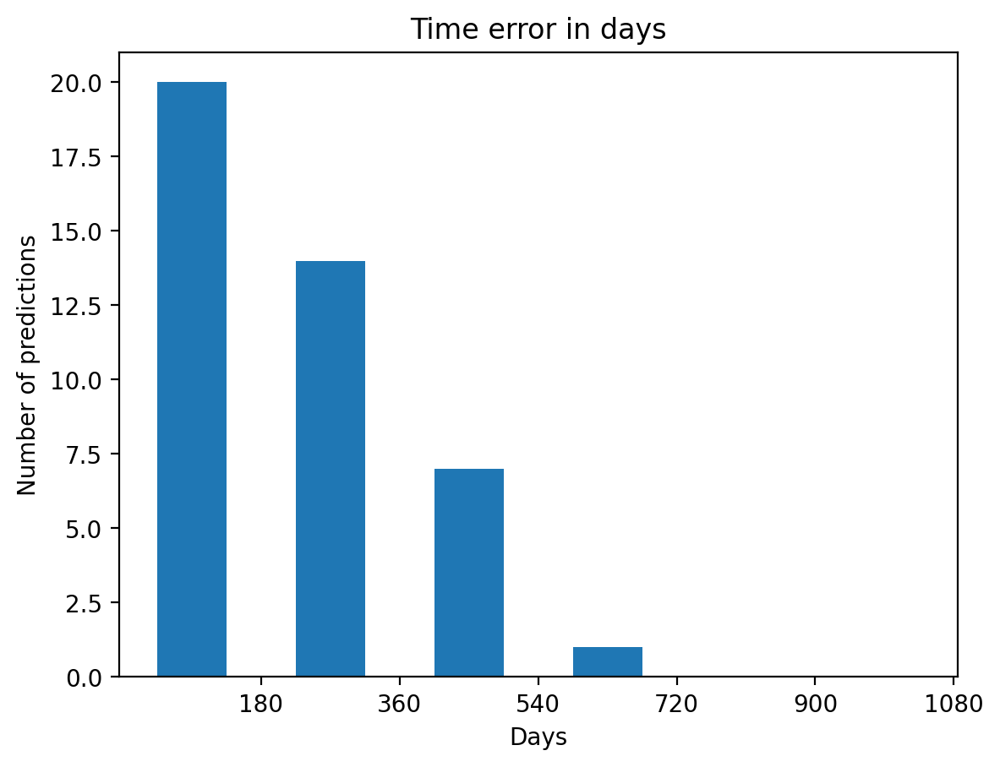

C-Index Censored:
-----------------
Fold 0
Concordance Index: 0.903
Number of concordant pairs: 224
Number of diconcordant pairs: 24
Fold 1
Concordance Index: 0.944
Number of concordant pairs: 306
Number of diconcordant pairs: 18
Fold 2
Concordance Index: 0.920
Number of concordant pairs: 309
Number of diconcordant pairs: 27
Fold 3
Concordance Index: 0.825
Number of concordant pairs: 238
Number of diconcordant pairs: 43
Fold 4
Concordance Index: 0.853
Number of concordant pairs: 221
Number of diconcordant pairs: 38
Macro-average Concordance Index: 0.889


C-Index IPCW:
-------------
Fold 0
IPCW Concordance Index: 0.719
Number of concordant pairs: 224
Number of diconcordant pairs: 24
Fold 1
IPCW Concordance Index: 0.917
Number of concordant pairs: 306
Number of diconcordant pairs: 18
Fold 2
IPCW Concordance Index: 0.912
Number of concordant pairs: 309
Number of diconcordant pairs: 27
Fold 3
IPCW Concordance Index: 0.701
Number of concordant pairs: 238
Number of diconcordant pairs: 43
Fo

In [13]:
run_pipeline(encoded_unimputed_df_0.drop(columns=categorical_cols), 
    ['EVENT', 'TIME_IN_DAYS'], 
    "gbsa", 
    folds, 
    numerical_cols_to_impute
            )

### c-GBSA

Running fold 0 ...
0.55


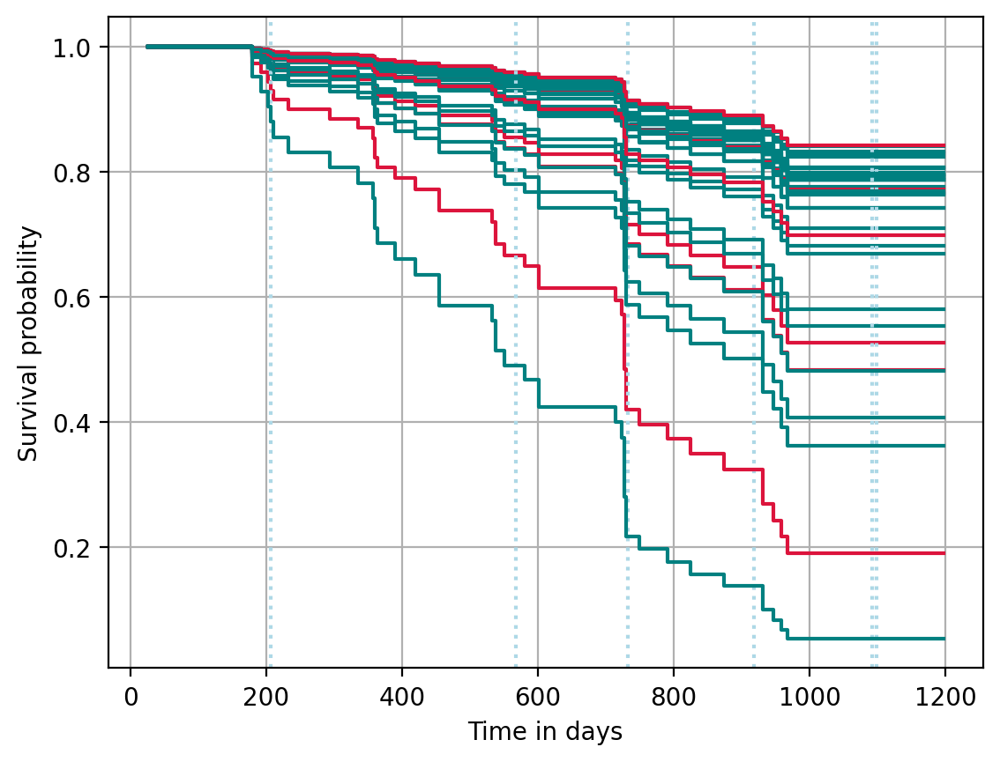

  0%|          | 0/44 [00:00<?, ?it/s]

c-gbsa SHAP values


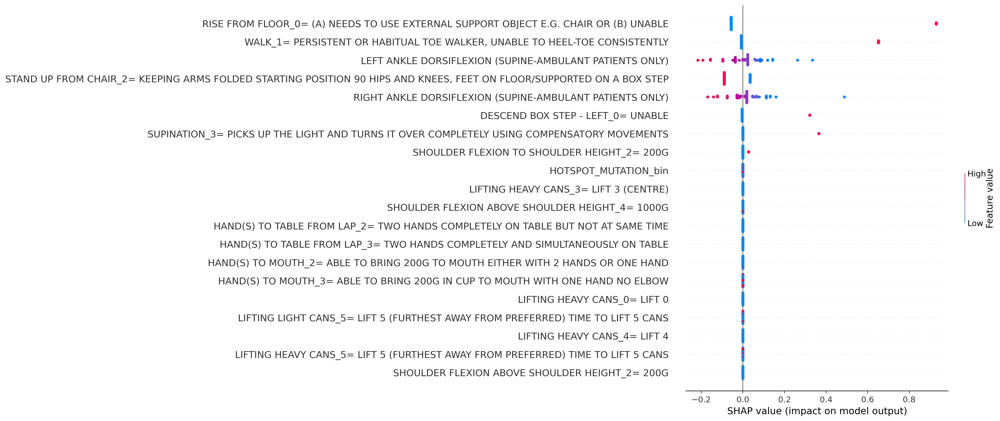

None
Running fold 1 ...
0.5


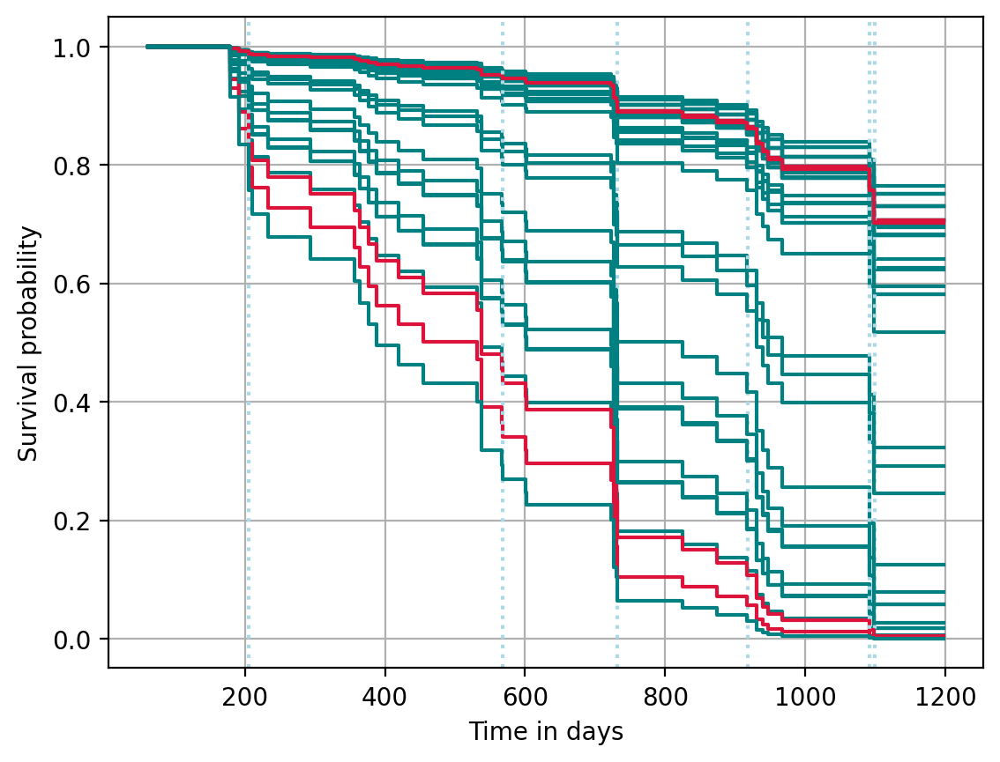

  0%|          | 0/44 [00:00<?, ?it/s]

c-gbsa SHAP values


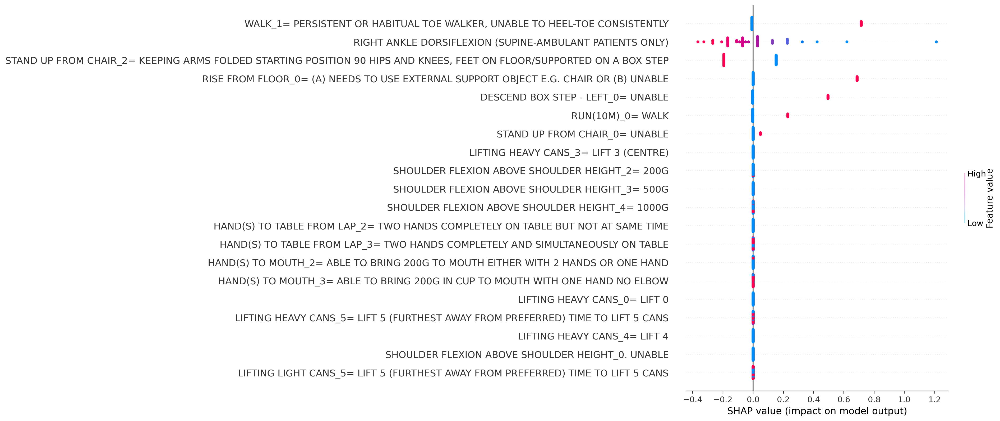

None
Running fold 2 ...
0.55


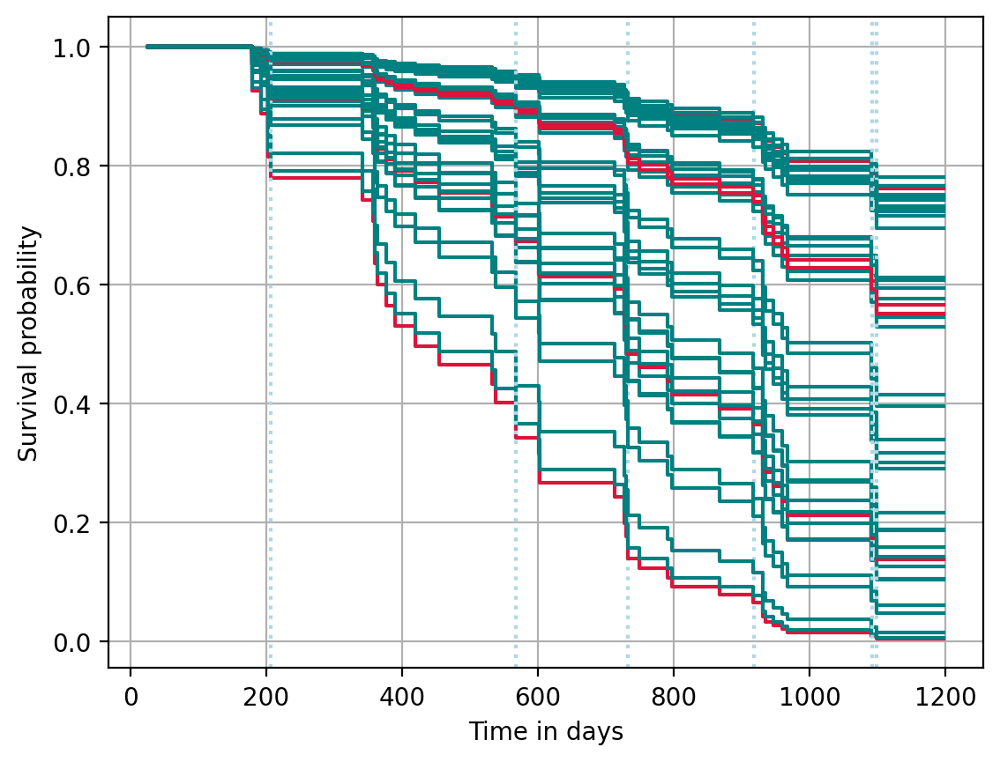

  0%|          | 0/44 [00:00<?, ?it/s]

c-gbsa SHAP values


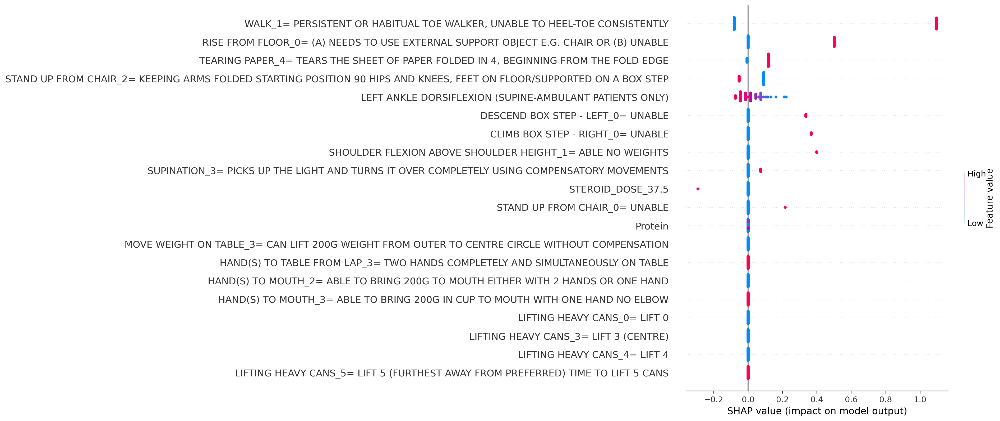

None
Running fold 3 ...
0.5


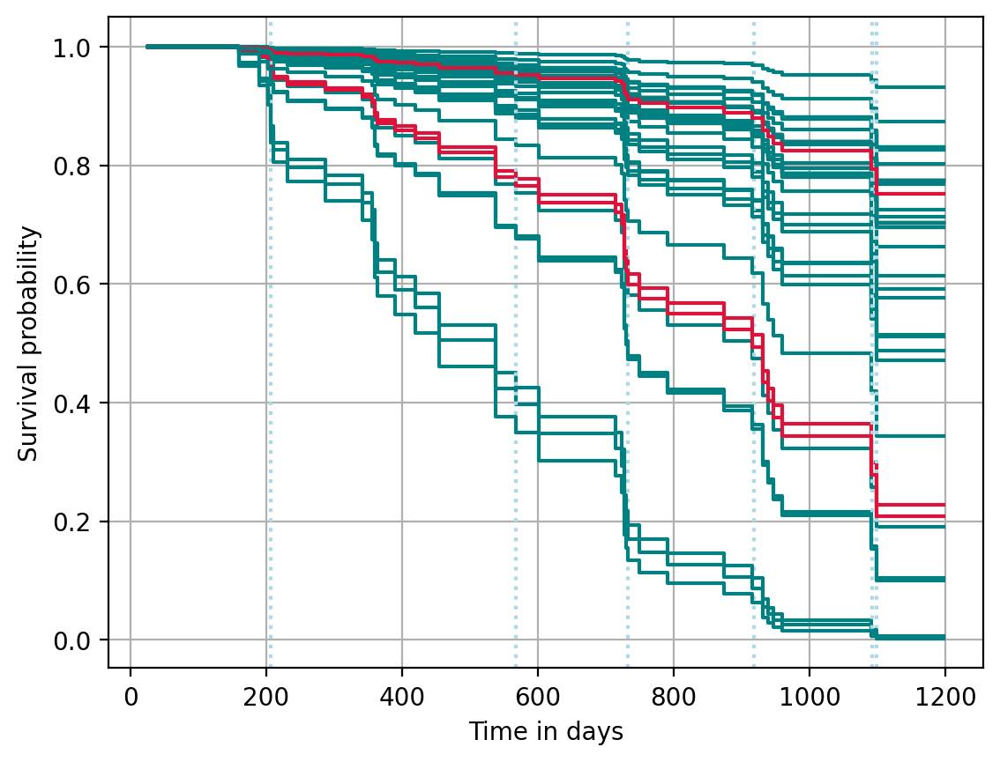

  0%|          | 0/44 [00:00<?, ?it/s]

c-gbsa SHAP values


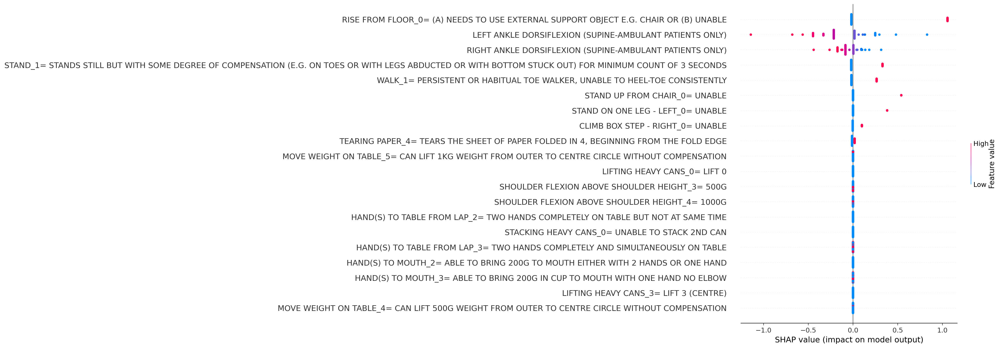

None
Running fold 4 ...
0.5


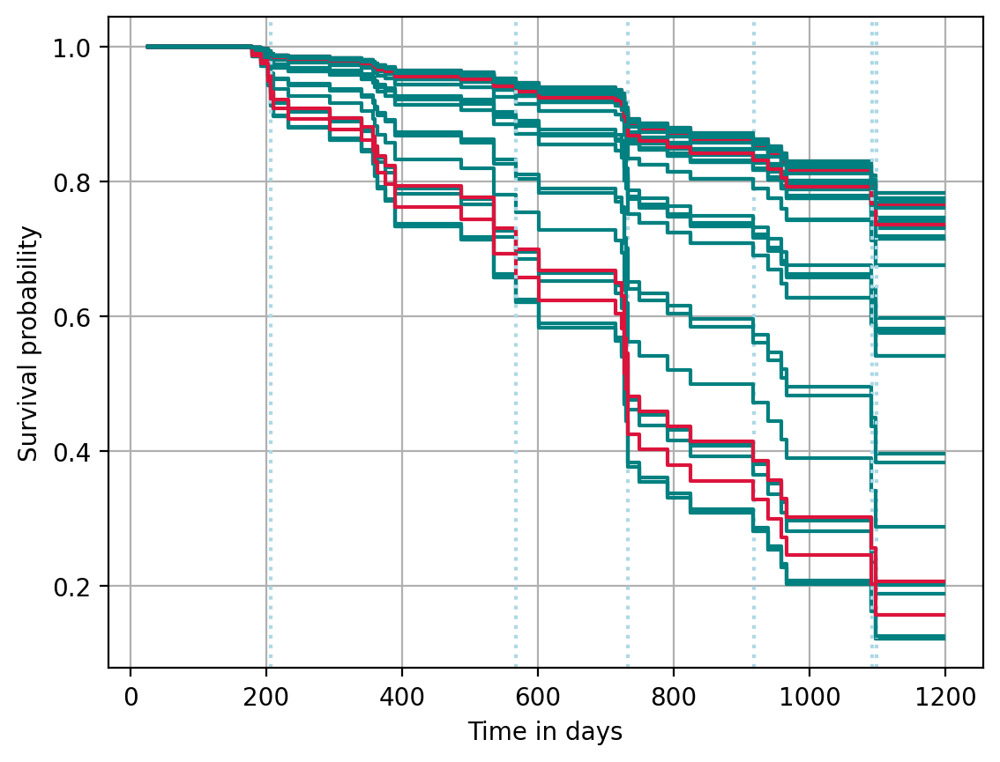

  0%|          | 0/43 [00:00<?, ?it/s]

c-gbsa SHAP values


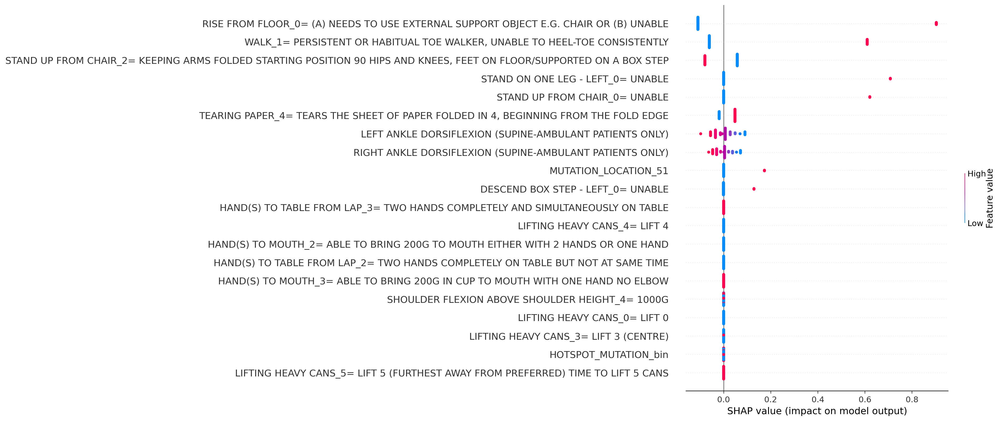

None


Micro-averaged classification report:
-------------------------------------
              precision    recall  f1-score   support

           0       0.91      0.83      0.87       167
           1       0.58      0.73      0.64        52

    accuracy                           0.81       219
   macro avg       0.74      0.78      0.76       219
weighted avg       0.83      0.81      0.82       219



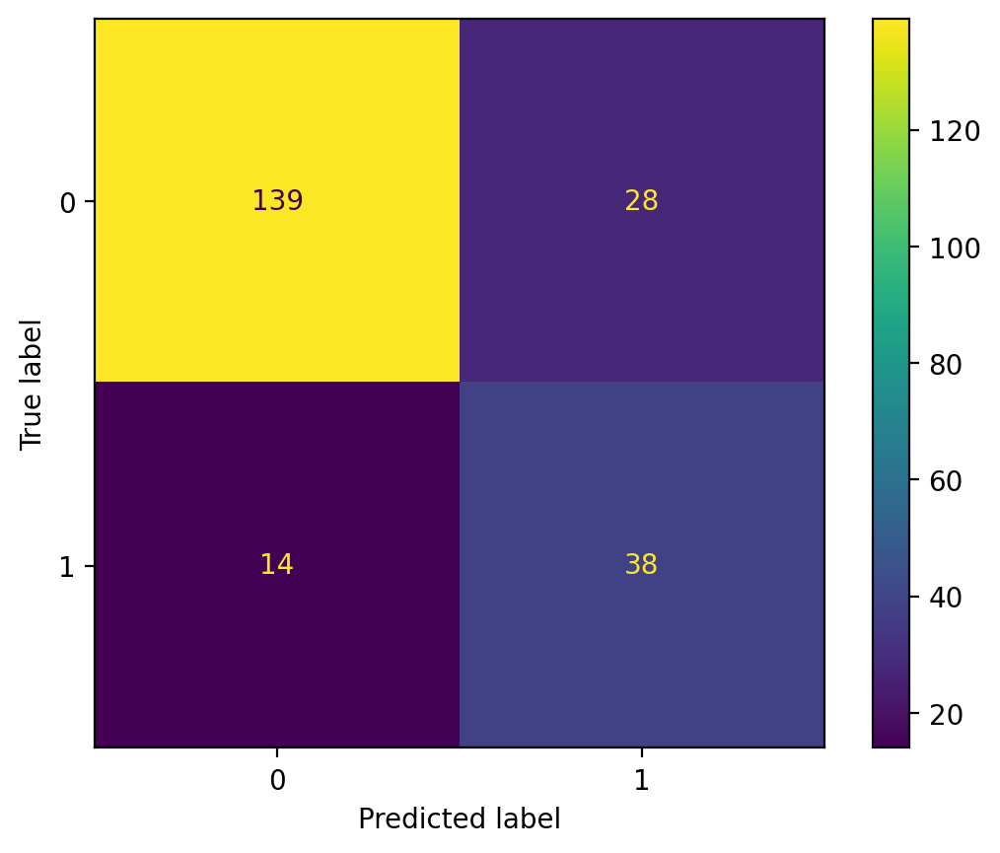

Time mean absolute error: 295.137



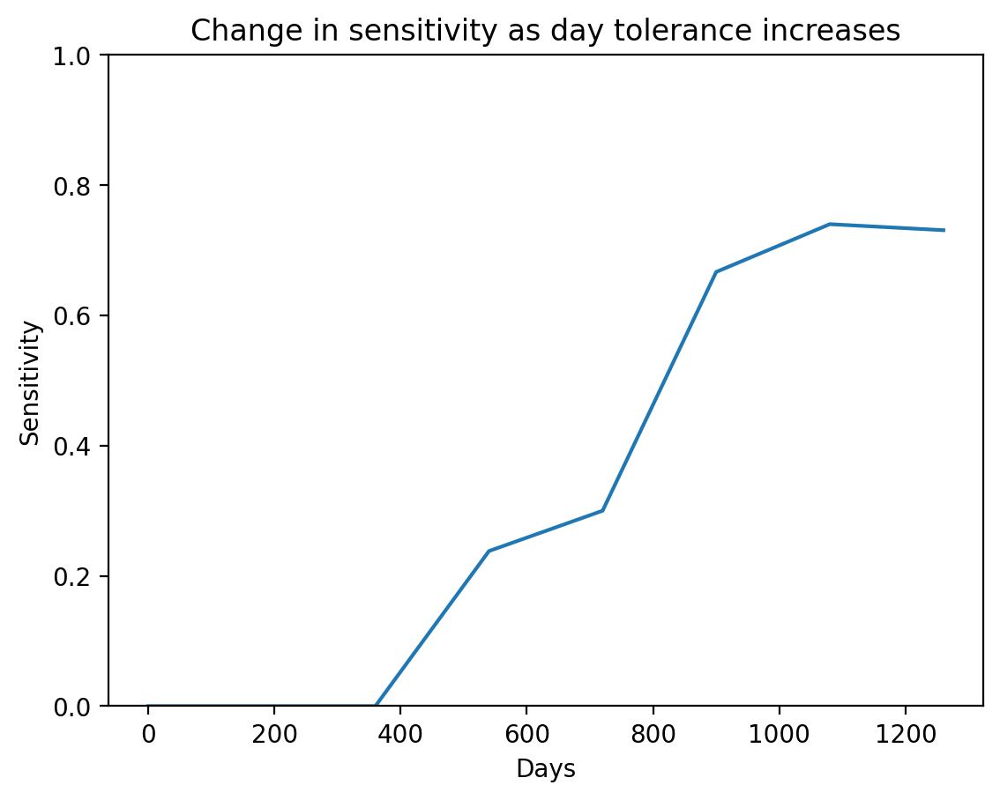

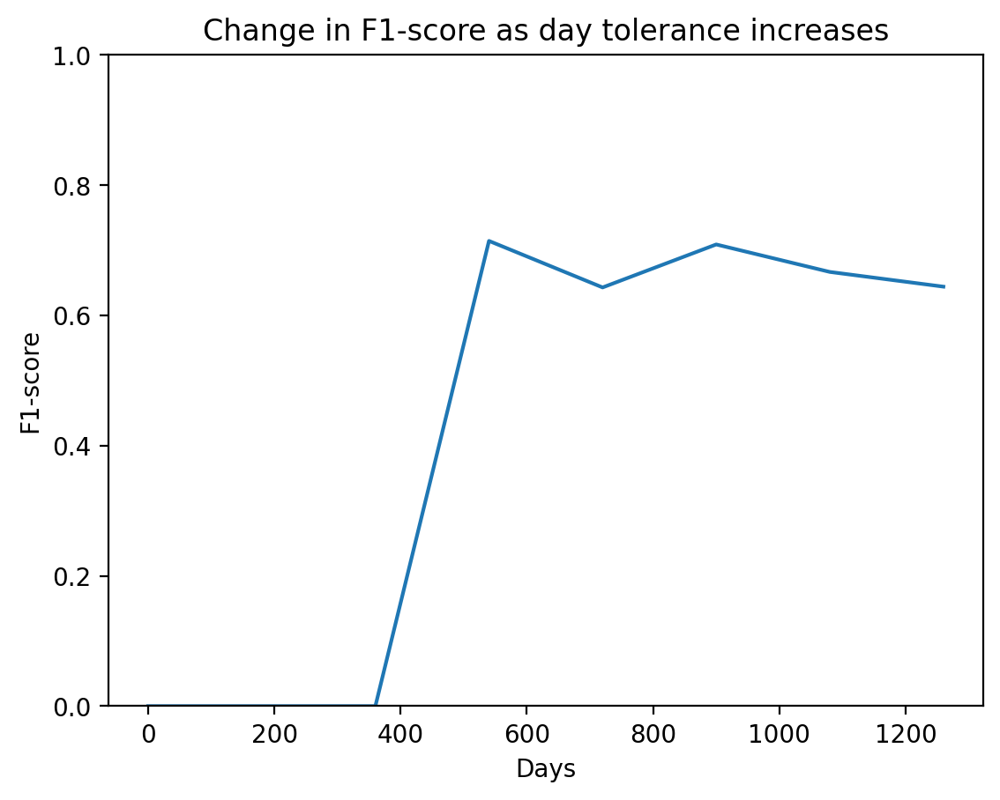

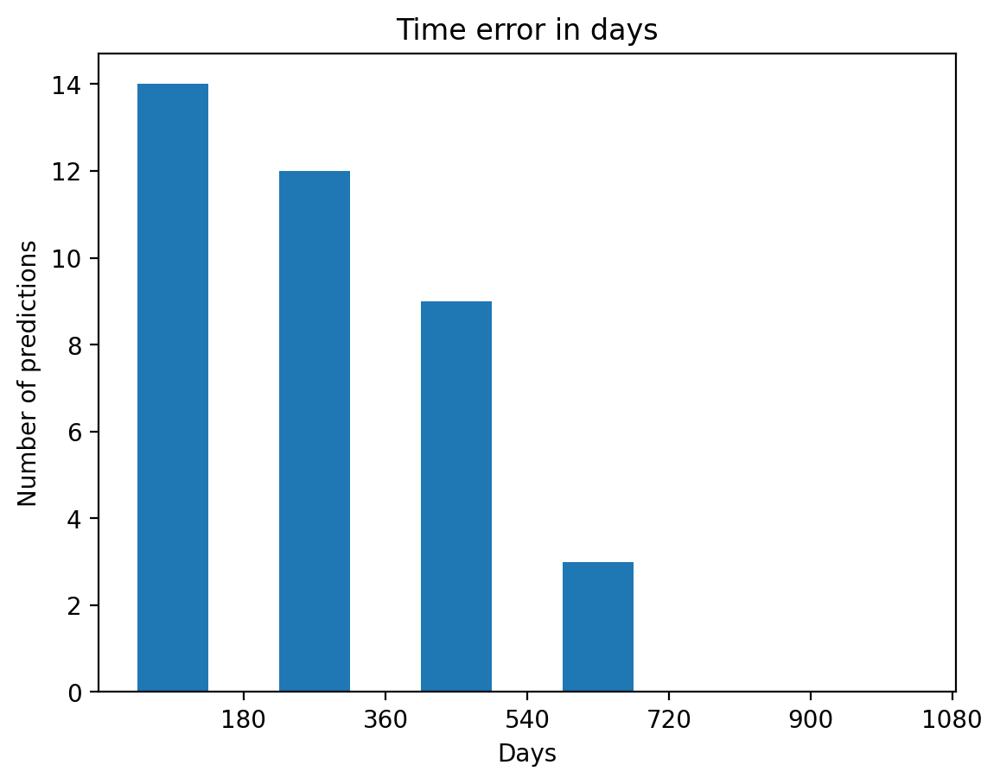

C-Index Censored:
-----------------
Fold 0
Concordance Index: 0.903
Number of concordant pairs: 224
Number of diconcordant pairs: 24
Fold 1
Concordance Index: 0.917
Number of concordant pairs: 297
Number of diconcordant pairs: 27
Fold 2
Concordance Index: 0.872
Number of concordant pairs: 293
Number of diconcordant pairs: 43
Fold 3
Concordance Index: 0.842
Number of concordant pairs: 250
Number of diconcordant pairs: 45
Fold 4
Concordance Index: 0.931
Number of concordant pairs: 240
Number of diconcordant pairs: 17
Macro-average Concordance Index: 0.893


C-Index IPCW:
-------------
Fold 0
IPCW Concordance Index: 0.550
Number of concordant pairs: 224
Number of diconcordant pairs: 24
Fold 1
IPCW Concordance Index: 0.874
Number of concordant pairs: 297
Number of diconcordant pairs: 27
Fold 2
IPCW Concordance Index: 0.854
Number of concordant pairs: 293
Number of diconcordant pairs: 43
Fold 3
IPCW Concordance Index: 0.852
Number of concordant pairs: 250
Number of diconcordant pairs: 45
Fo

In [14]:
run_pipeline(encoded_unimputed_df_0.drop(columns=categorical_cols), 
    ['EVENT', 'TIME_IN_DAYS'], 
    "c-gbsa", 
    folds, 
    numerical_cols_to_impute
            )

### ExtraTrees

Running fold 0 ...
0.5


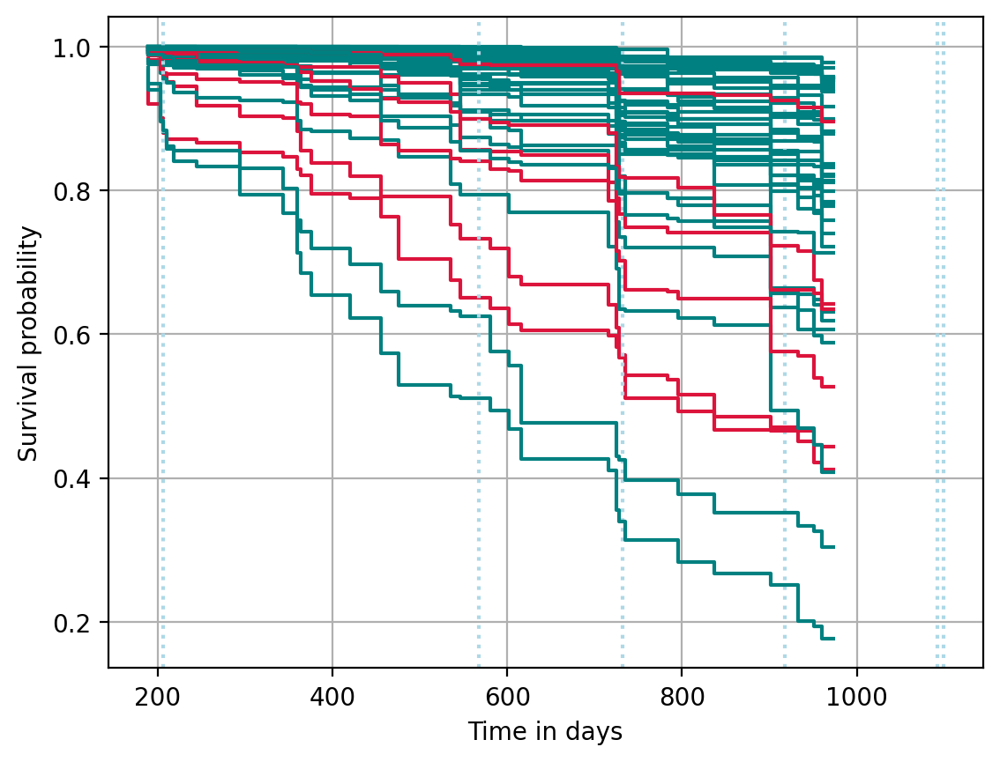

  0%|          | 0/44 [00:00<?, ?it/s]

xst SHAP values


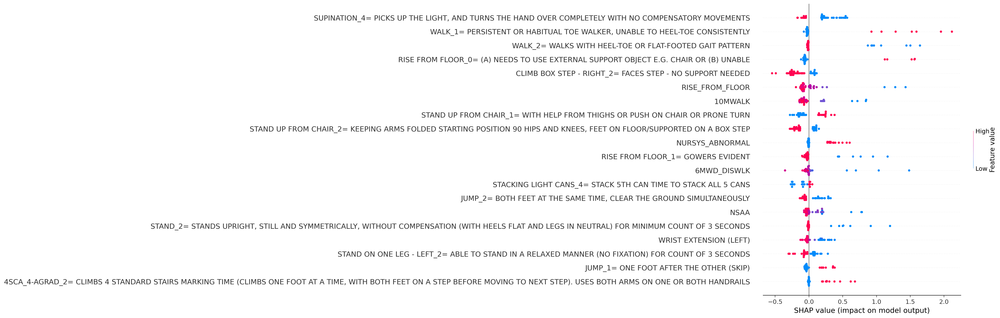

None
Running fold 1 ...
0.55


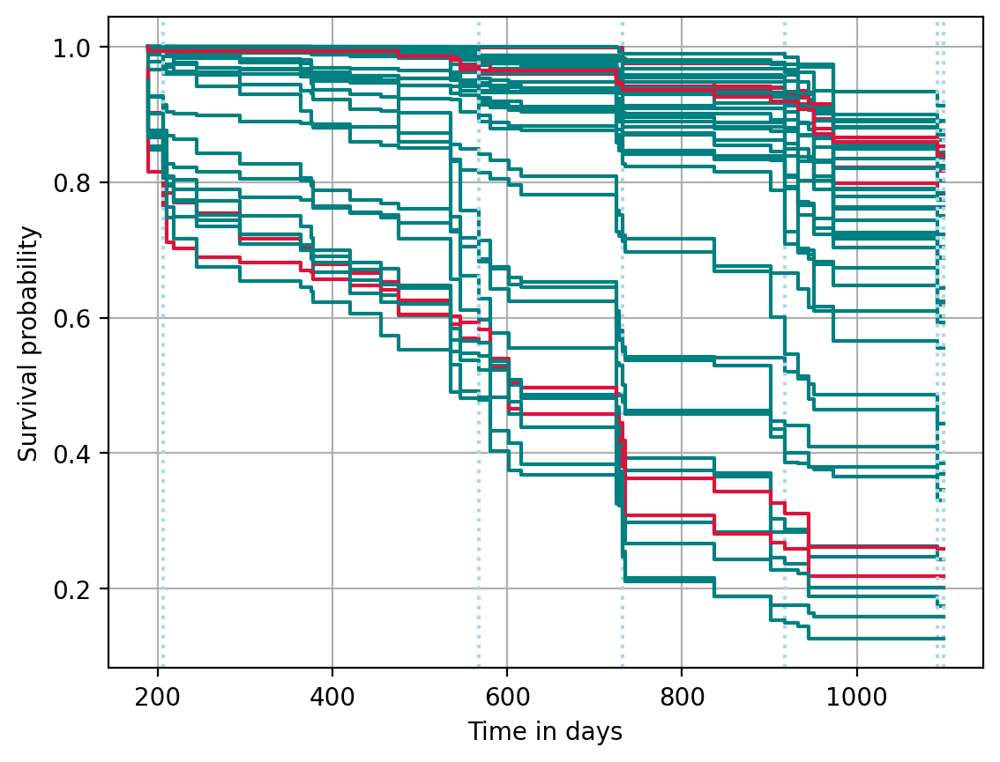

  0%|          | 0/44 [00:00<?, ?it/s]

xst SHAP values


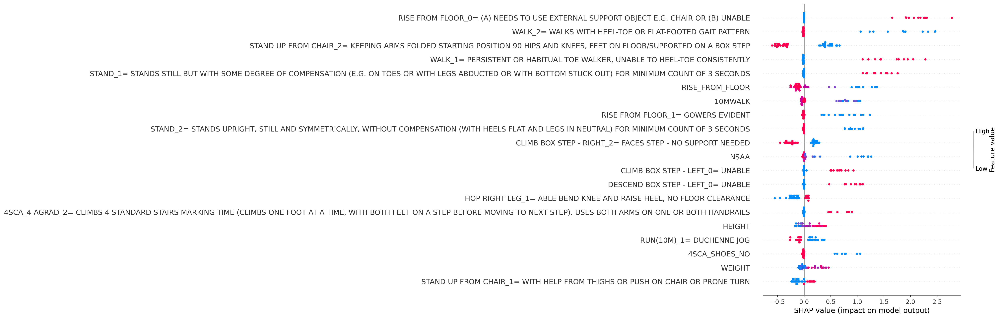

None
Running fold 2 ...
0.6000000000000001


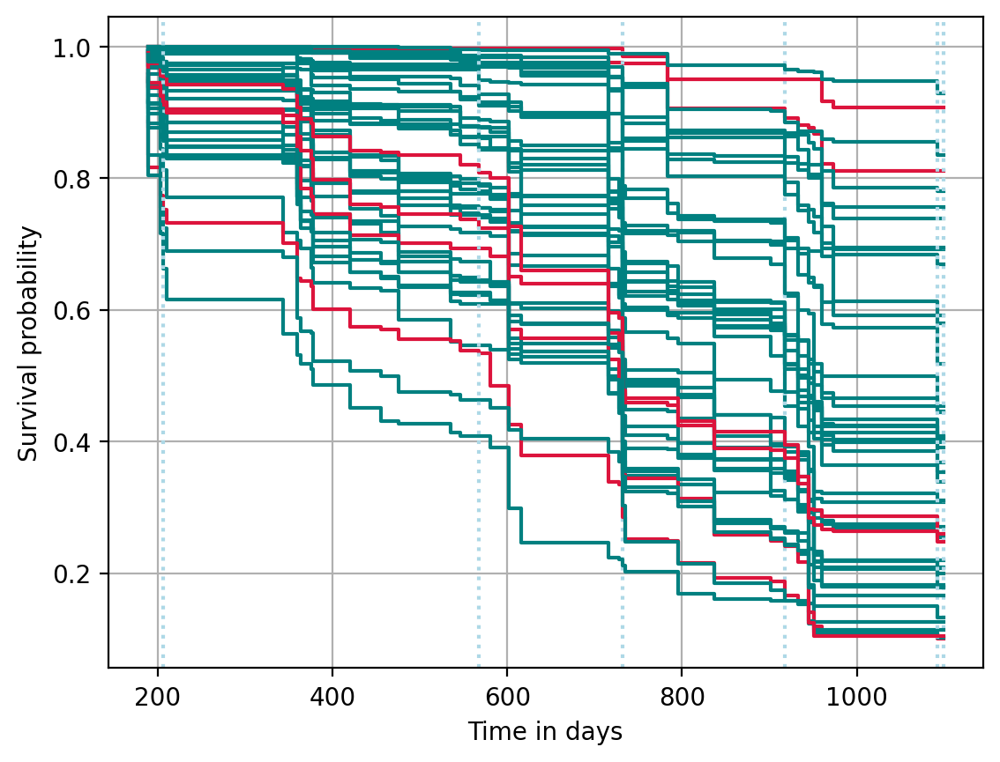

  0%|          | 0/44 [00:00<?, ?it/s]

xst SHAP values


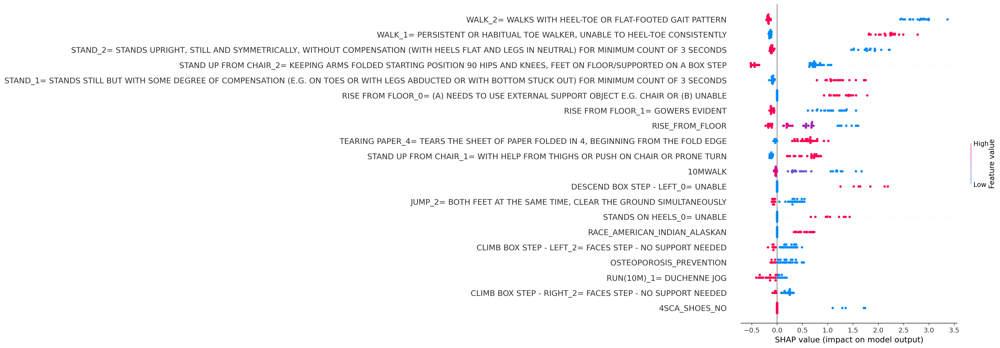

None
Running fold 3 ...
0.55


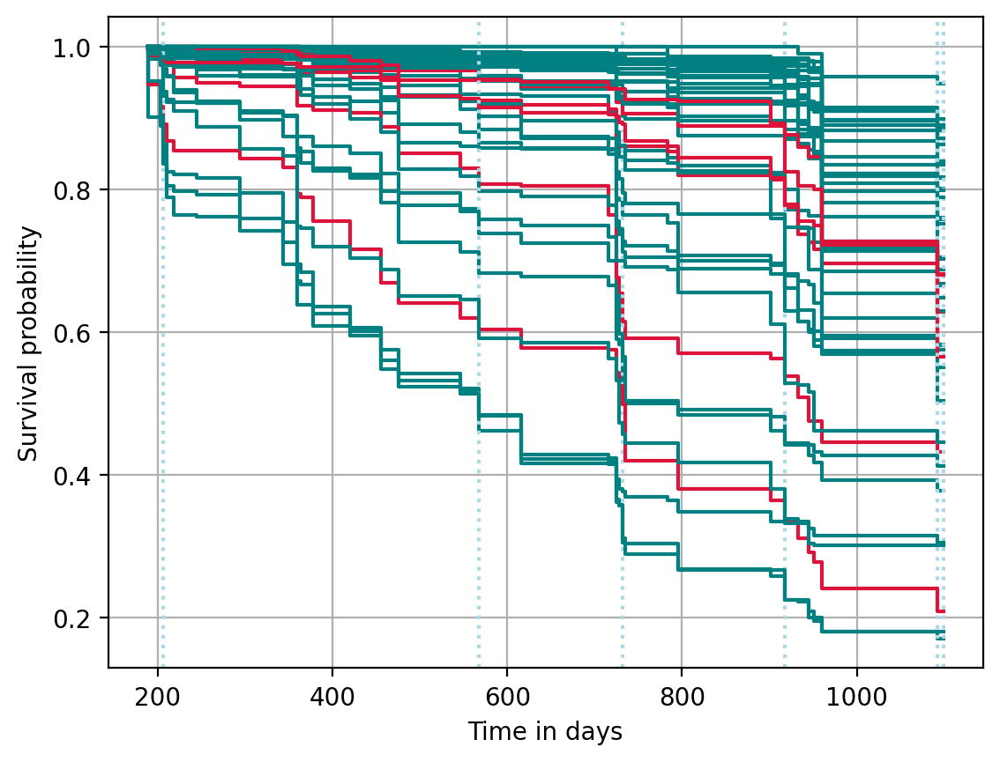

  0%|          | 0/44 [00:00<?, ?it/s]

xst SHAP values


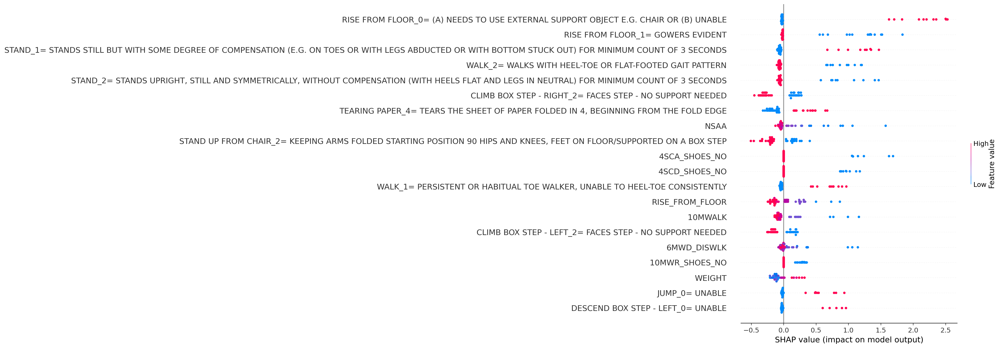

None
Running fold 4 ...
0.55


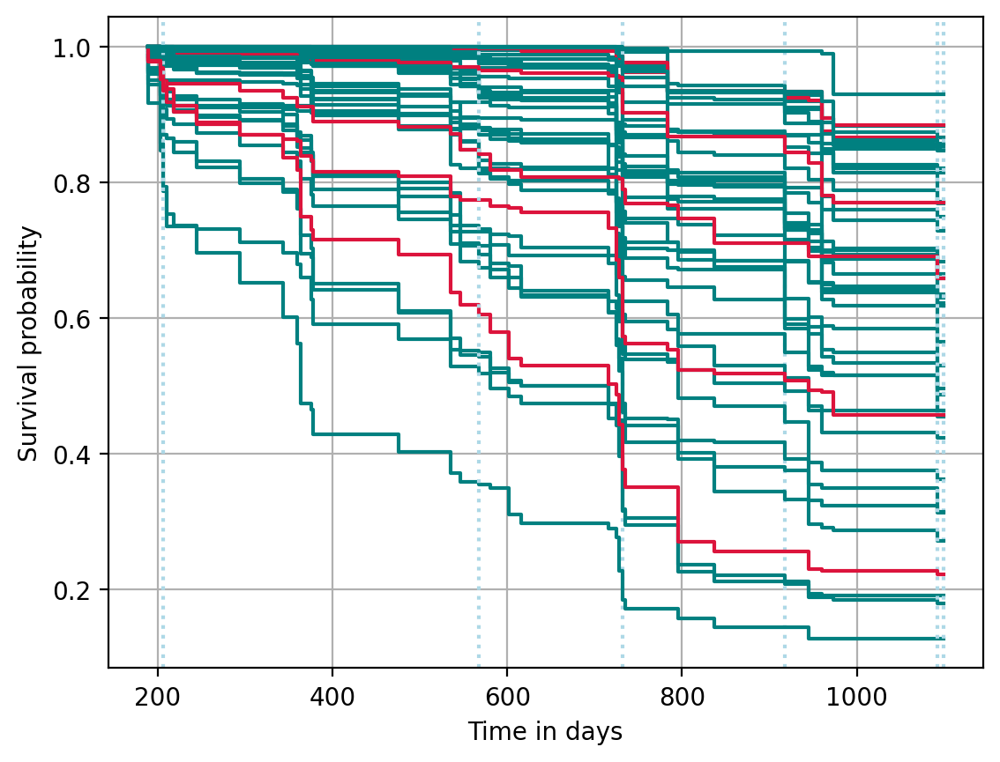

  0%|          | 0/43 [00:00<?, ?it/s]

xst SHAP values


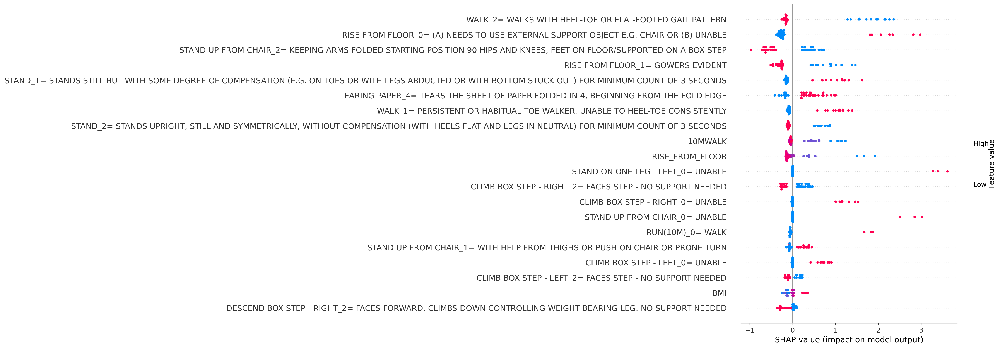

None


Micro-averaged classification report:
-------------------------------------
              precision    recall  f1-score   support

           0       0.92      0.78      0.84       167
           1       0.53      0.79      0.63        52

    accuracy                           0.78       219
   macro avg       0.72      0.78      0.74       219
weighted avg       0.83      0.78      0.79       219



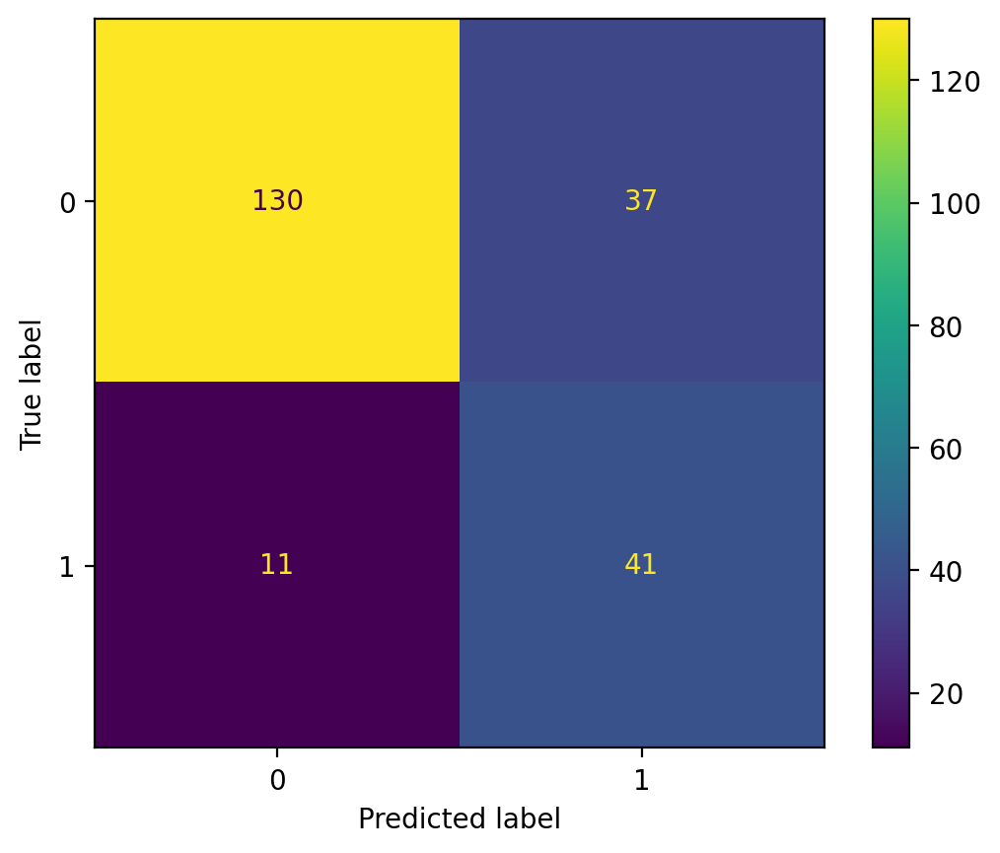

Time mean absolute error: 238.157



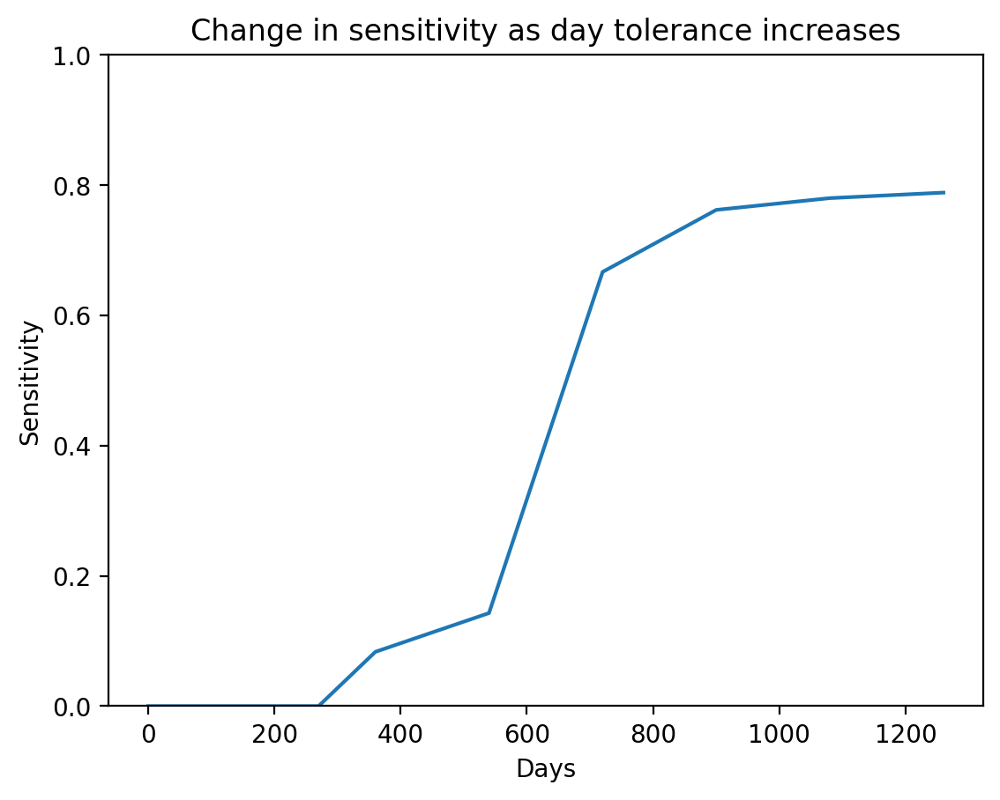

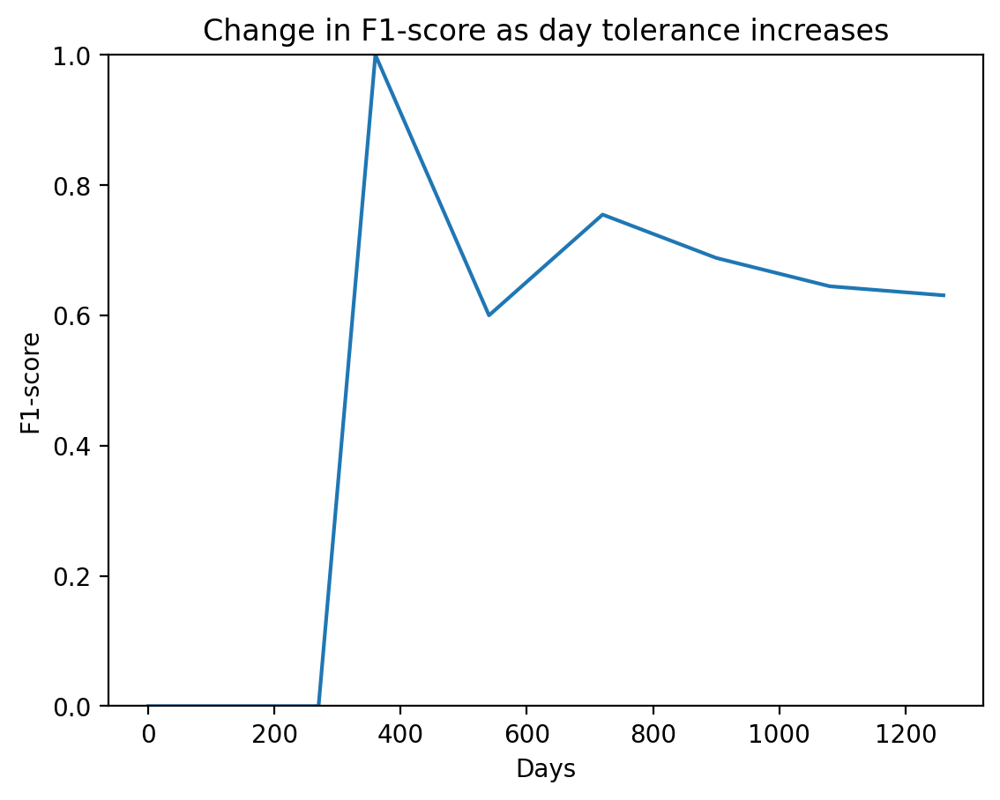

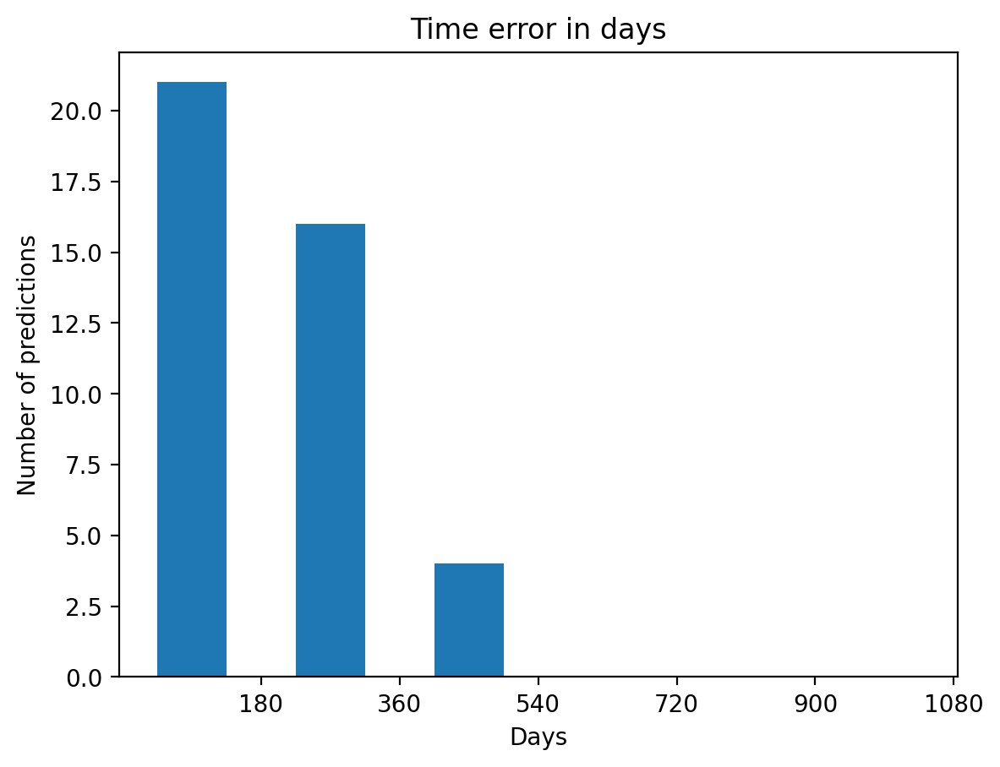

C-Index Censored:
-----------------
Fold 0
Concordance Index: 0.887
Number of concordant pairs: 220
Number of diconcordant pairs: 28
Fold 1
Concordance Index: 0.917
Number of concordant pairs: 297
Number of diconcordant pairs: 27
Fold 2
Concordance Index: 0.887
Number of concordant pairs: 298
Number of diconcordant pairs: 38
Fold 3
Concordance Index: 0.883
Number of concordant pairs: 265
Number of diconcordant pairs: 35
Fold 4
Concordance Index: 0.965
Number of concordant pairs: 250
Number of diconcordant pairs: 9
Macro-average Concordance Index: 0.908


C-Index IPCW:
-------------
Fold 0
IPCW Concordance Index: 0.733
Number of concordant pairs: 220
Number of diconcordant pairs: 28
Fold 1
IPCW Concordance Index: 0.880
Number of concordant pairs: 297
Number of diconcordant pairs: 27
Fold 2
IPCW Concordance Index: 0.873
Number of concordant pairs: 298
Number of diconcordant pairs: 38
Fold 3
IPCW Concordance Index: 0.793
Number of concordant pairs: 265
Number of diconcordant pairs: 35
Fol

In [15]:
run_pipeline(encoded_unimputed_df_0.drop(columns=categorical_cols), 
    ['EVENT', 'TIME_IN_DAYS'], 
    "xst", 
    folds, 
    numerical_cols_to_impute
            )